In [4]:
import os, subprocess, sys

# Protobuf safety (harmless if TF absent)
os.environ["PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION"] = "python"

def have(pkg):
    import importlib.util
    return importlib.util.find_spec(pkg) is not None

# Core packages imported normally
for pkg in ["timm", "sklearn", "tqdm", "faiss", "xgboost", "optuna"]:
    name = {"sklearn": "scikit-learn", "faiss": "faiss-cpu"}.get(pkg, pkg)
    if have(pkg):
        print(f"  ok  {name}")
    else:
        print(f"  installing {name} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", name, "-q"], check=False)

# Optional packages checked WITHOUT importing (they can pull in TF/protobuf)
for pkg in ["mediapipe", "insightface", "retinaface"]:
    print(f"  {'ok ' if have(pkg) else '-- '} {pkg} ({'available' if have(pkg) else 'optional, will fallback'})")

import torch
print(f"\nPyTorch : {torch.__version__}")
print(f"GPU     : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
print("\nPackages ready.")

  ok  timm
  ok  scikit-learn
  ok  tqdm
  ok  faiss-cpu
  ok  xgboost
  ok  optuna
  ok  mediapipe (available)
  ok  insightface (available)
  ok  retinaface (available)

PyTorch : 2.5.1+cu121
GPU     : True
GPU name: NVIDIA GeForce RTX 3060 Laptop GPU

Packages ready.


In [6]:
import os
os.environ["PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION"] = "python"

import sys, cv2, json, pickle, time, shutil, warnings, random, gc, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from pathlib import Path
from tqdm import tqdm
from collections import Counter
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
import timm

from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support,
                             roc_curve, auc)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE

# ── Memory cleanup helper — CALL THIS to prevent crashes ──────────────
def free():
    """Free GPU + RAM. Call after any heavy GPU operation."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

# ── Device ────────────────────────────────────────────────────────────
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42); np.random.seed(42); random.seed(42)
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True

# ── Paths (EDIT THESE if your folders differ) ─────────────────────────
FACE_SHAPE_DIR = Path(r"data/face_shape/training_set")
CELEBA_DIR     = Path(r"data/celeba")
WORK_DIR       = Path(r"workdir")
PROCESSED_DIR  = WORK_DIR / "processed"
SPLIT_DIR      = WORK_DIR / "split"
EMBEDDINGS_DIR = WORK_DIR / "embeddings"
MODELS_DIR     = WORK_DIR / "models"
OUTPUTS_DIR    = WORK_DIR / "outputs"
HAIRSTYLE_DIR  = WORK_DIR / "hairstyles"
for d in [PROCESSED_DIR, SPLIT_DIR, EMBEDDINGS_DIR, MODELS_DIR, OUTPUTS_DIR, HAIRSTYLE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CELEB_EMBED_PATH = EMBEDDINGS_DIR / "celeb_embeddings.npy"
CELEB_META_PATH  = EMBEDDINGS_DIR / "celeb_metadata.csv"
MODEL_PATH       = MODELS_DIR / "face_shape_classifier.pt"
PHASE1_PATH      = MODELS_DIR / "efficientnet_phase1.pt"

# ── Hyperparameters ───────────────────────────────────────────────────
FACE_SHAPES     = ["Heart", "Oblong", "Oval", "Round", "Square"]
NUM_CLASSES     = 5
IMG_SIZE        = (224, 224)
FACE_ALIGN_SIZE = (112, 112)
EMBED_DIM       = 512
BATCH_SIZE      = 32          # safe for 6GB VRAM
INFER_BATCH     = 16          # smaller for inference / embedding extraction
LR_HEAD         = 1e-3
LR_FINETUNE     = 3e-5
EPOCHS_HEAD     = 30
EPOCHS_FINETUNE = 60
DROPOUT_RATE    = 0.4
LABEL_SMOOTHING = 0.1
TOP_N_CELEB     = 5
TEST_SPLIT      = 0.15
RANDOM_SEED     = 42

# ── Haar cascade (robust path) ────────────────────────────────────────
HAAR_XML = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
if not os.path.isfile(HAAR_XML):
    import urllib.request
    HAAR_XML = str(WORK_DIR / "haarcascade_frontalface_default.xml")
    if not os.path.isfile(HAAR_XML):
        urllib.request.urlretrieve(
            "https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml",
            HAAR_XML)

# ── Face detection / alignment helpers ────────────────────────────────
ARCFACE_REF = np.float32([[38.2946,51.6963],[73.5318,51.5014],[56.0252,71.7366],
                          [41.5493,92.3655],[70.7299,92.2041]])

def load_rgb(path):
    img = cv2.imread(str(path))
    if img is None: raise FileNotFoundError(path)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def detect_haar(img_rgb):
    det = cv2.CascadeClassifier(HAAR_XML)
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    faces = det.detectMultiScale(gray, 1.1, 5, minSize=(60,60))
    return [{"bbox":[x,y,x+w,y+h], "lms":None, "score":float(w*h)} for (x,y,w,h) in faces]

def detect_retinaface(img_rgb):
    try:
        from retinaface import RetinaFace
        res = RetinaFace.detect_faces(cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR))
        if not isinstance(res, dict): return []
        out = []
        for _, f in res.items():
            fa = f.get("facial_area",[0,0,0,0]); lms = f.get("landmarks",{})
            pts = np.float32([lms.get("right_eye",[0,0]), lms.get("left_eye",[0,0]),
                              lms.get("nose",[0,0]), lms.get("mouth_right",[0,0]),
                              lms.get("mouth_left",[0,0])])
            out.append({"bbox":fa, "lms":pts, "score":f.get("score",1.0)})
        return sorted(out, key=lambda x:x["score"], reverse=True)
    except Exception:
        return []

def align_face(img_rgb, lms, size=(112,112)):
    dst = ARCFACE_REF.copy(); dst[:,0]*=size[0]/112.0; dst[:,1]*=size[1]/112.0
    T,_ = cv2.estimateAffinePartial2D(lms, dst, method=cv2.LMEDS)
    if T is None: return cv2.resize(img_rgb, size)
    return cv2.warpAffine(img_rgb, T, size, flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)

def detect_and_align(img_rgb, size=(224,224)):
    dets = detect_retinaface(img_rgb) or detect_haar(img_rgb)
    if not dets: return None
    best = dets[0]
    if best["lms"] is not None and not np.all(best["lms"]==0):
        return cv2.resize(align_face(img_rgb, best["lms"], (112,112)), size)
    x1,y1,x2,y2 = [int(v) for v in best["bbox"]]; h,w = img_rgb.shape[:2]
    px,py = int((x2-x1)*0.1), int((y2-y1)*0.1)
    crop = img_rgb[max(0,y1-py):min(h,y2+py), max(0,x1-px):min(w,x2+px)]
    return cv2.resize(crop, size) if crop.size else None

def crop_from_path(path, size=(224,224)):
    img = load_rgb(str(path)); face = detect_and_align(img, size)
    if face is None: raise ValueError(f"No face: {path}")
    return face

# ── Image transforms ──────────────────────────────────────────────────
train_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.RandomAffine(degrees=0, translate=(0.1,0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])
val_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

print(f"Device: {DEVICE}  ({torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU'})")
print(f"PyTorch {torch.__version__} | OpenCV {cv2.__version__} | NumPy {np.__version__}")
print(f"Face shape dir : {FACE_SHAPE_DIR.is_dir()}")
print(f"CelebA dir     : {CELEBA_DIR.is_dir()}")
print("Config loaded.")

Device: cuda  (NVIDIA GeForce RTX 3060 Laptop GPU)
PyTorch 2.5.1+cu121 | OpenCV 4.13.0 | NumPy 2.0.2
Face shape dir : True
CelebA dir     : True
Config loaded.


 class  count
 Heart    800
Oblong    800
  Oval    800
 Round    800
Square    800

Total images: 4000


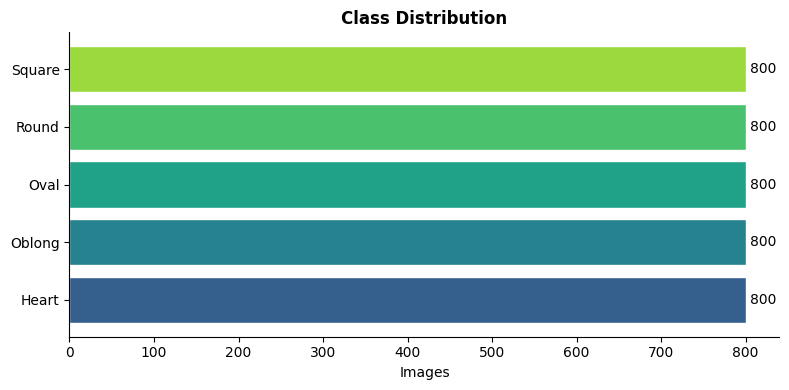

In [6]:
def scan_dataset(root, classes):
    rows = []
    for cls in classes:
        p = Path(root) / cls
        files = (list(p.glob("*.jpg")) + list(p.glob("*.png")) + list(p.glob("*.jpeg"))) if p.is_dir() else []
        rows.append({"class": cls, "count": len(files)})
    return pd.DataFrame(rows)

df = scan_dataset(FACE_SHAPE_DIR, FACE_SHAPES)
print(df.to_string(index=False))
print(f"\nTotal images: {df['count'].sum()}")

if df["count"].sum() > 0:
    fig, ax = plt.subplots(figsize=(8,4))
    colors = plt.cm.viridis(np.linspace(0.3, 0.85, len(FACE_SHAPES)))
    bars = ax.barh(df["class"], df["count"], color=colors, edgecolor="white")
    for bar, val in zip(bars, df["count"]):
        ax.text(bar.get_width()+5, bar.get_y()+bar.get_height()/2, str(val), va="center")
    ax.set_xlabel("Images"); ax.set_title("Class Distribution", fontweight="bold")
    ax.spines[["top","right"]].set_visible(False)
    plt.tight_layout(); plt.show()
    fig.savefig(str(OUTPUTS_DIR/"class_distribution.png"), dpi=150, bbox_inches="tight")
    plt.close(fig)
free()

In [8]:
def preprocess_dataset(raw_dir, out_dir, classes):
    Path(out_dir).mkdir(parents=True, exist_ok=True)
    for cls in classes:
        in_cls, out_cls = Path(raw_dir)/cls, Path(out_dir)/cls
        out_cls.mkdir(parents=True, exist_ok=True)
        if not in_cls.is_dir(): continue
        files = list(in_cls.glob("*.jpg")) + list(in_cls.glob("*.png")) + list(in_cls.glob("*.jpeg"))
        ok = fail = skip = 0
        for fpath in tqdm(files, desc=f"  {cls}", leave=False):
            dst = out_cls / (fpath.stem + ".jpg")
            if dst.exists(): skip += 1; continue
            try:
                face = crop_from_path(str(fpath), IMG_SIZE)
                cv2.imwrite(str(dst), cv2.cvtColor(face, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 95])
                ok += 1
            except Exception:
                fail += 1
        print(f"  {cls:10s}  saved={ok}  failed={fail}  skipped={skip}")

already = any((Path(PROCESSED_DIR)/c).is_dir() and len(list((Path(PROCESSED_DIR)/c).glob("*.jpg")))>0 for c in FACE_SHAPES)
if already:
    print("Processed images already exist - skipping.")
else:
    total = sum(len(list((Path(FACE_SHAPE_DIR)/c).glob("*.jpg"))) for c in FACE_SHAPES if (Path(FACE_SHAPE_DIR)/c).is_dir())
    if total == 0:
        print("No images found - check FACE_SHAPE_DIR in Cell 1.")
    else:
        print(f"Processing {total} images...")
        preprocess_dataset(FACE_SHAPE_DIR, PROCESSED_DIR, FACE_SHAPES)

for cls in FACE_SHAPES:
    n = len(list((Path(PROCESSED_DIR)/cls).glob("*.jpg"))) if (Path(PROCESSED_DIR)/cls).is_dir() else 0
    print(f"  {cls:10s}: {n}")
free()

Processed images already exist - skipping.
  Heart     : 795
  Oblong    : 799
  Oval      : 796
  Round     : 796
  Square    : 798


In [10]:
def split_dataset(src_dir, out_dir, train_r=0.70, val_r=0.15):
    random.seed(RANDOM_SEED)
    for cls in FACE_SHAPES:
        cls_dir = Path(src_dir)/cls
        if not cls_dir.is_dir(): continue
        files = list(cls_dir.glob("*.jpg")) + list(cls_dir.glob("*.png")) + list(cls_dir.glob("*.jpeg"))
        random.shuffle(files); n = len(files)
        cuts = {"train": files[:int(n*train_r)],
                "val":   files[int(n*train_r):int(n*(train_r+val_r))],
                "test":  files[int(n*(train_r+val_r)):]}
        for split, sf in cuts.items():
            dst = Path(out_dir)/split/cls; dst.mkdir(parents=True, exist_ok=True)
            for f in sf:
                d = dst/f.name
                if not d.exists(): shutil.copy2(f, d)
        print(f"  {cls:10s}  train={len(cuts['train'])}  val={len(cuts['val'])}  test={len(cuts['test'])}")

split_done = (Path(SPLIT_DIR)/"train").is_dir() and any(
    len(list((Path(SPLIT_DIR)/"train"/c).glob("*.jpg")))>0 for c in FACE_SHAPES if (Path(SPLIT_DIR)/"train"/c).is_dir())
if split_done:
    print("Split already exists.")
else:
    src = str(PROCESSED_DIR) if any((Path(PROCESSED_DIR)/c).is_dir() and len(list((Path(PROCESSED_DIR)/c).glob("*.jpg")))>0 for c in FACE_SHAPES) else str(FACE_SHAPE_DIR)
    split_dataset(src, SPLIT_DIR)

for split in ["train","val","test"]:
    p = Path(SPLIT_DIR)/split
    if p.is_dir():
        total = sum(len(list((p/c).glob("*.jpg"))) for c in FACE_SHAPES if (p/c).is_dir())
        print(f"  {split:6s}: {total}")
free()

Split already exists.
  train : 2787
  val   : 597
  test  : 600


In [12]:
class FaceShapeDataset(Dataset):
    def __init__(self, root_dir, classes, transform=None):
        self.transform = transform; self.samples = []
        self.class_to_idx = {c:i for i,c in enumerate(classes)}
        for cls in classes:
            cls_dir = Path(root_dir)/cls
            if not cls_dir.is_dir(): continue
            for f in cls_dir.glob("*.jpg"):
                self.samples.append((str(f), self.class_to_idx[cls]))
    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, IMG_SIZE)
        if self.transform: img = self.transform(img)
        return img, label

TRAIN_DIR, VAL_DIR, TEST_DIR = (Path(SPLIT_DIR)/"train", Path(SPLIT_DIR)/"val", Path(SPLIT_DIR)/"test")
if not TRAIN_DIR.is_dir(): TRAIN_DIR = VAL_DIR = TEST_DIR = FACE_SHAPE_DIR

train_dataset = FaceShapeDataset(TRAIN_DIR, FACE_SHAPES, transform=train_transform)
val_dataset   = FaceShapeDataset(VAL_DIR,   FACE_SHAPES, transform=val_transform)
test_dataset  = FaceShapeDataset(TEST_DIR,  FACE_SHAPES, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=False)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False)

labels_all = [s[1] for s in train_dataset.samples]
counts = Counter(labels_all)
class_weights = torch.tensor(
    [len(labels_all)/(NUM_CLASSES*counts.get(i,1)) for i in range(NUM_CLASSES)],
    dtype=torch.float32).to(DEVICE)

with open(str(MODELS_DIR/"class_info.pkl"), "wb") as f:
    pickle.dump({"class_names": FACE_SHAPES, "class_to_idx": train_dataset.class_to_idx}, f)

print(f"Train {len(train_dataset)} | Val {len(val_dataset)} | Test {len(test_dataset)}")
print(f"Class weights: {[round(float(w),3) for w in class_weights]}")
print("DataLoaders ready.")

Train 2787 | Val 597 | Test 600
Class weights: [1.003, 0.997, 1.001, 1.001, 0.999]
DataLoaders ready.


In [14]:
class HairifyModel(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, dropout=DROPOUT_RATE, freeze_base=True, pretrained=True):
        super().__init__()
        self.base = timm.create_model("efficientnet_b3", pretrained=pretrained,
                                      num_classes=0, global_pool="avg")
        feat = self.base.num_features
        if freeze_base:
            for p in self.base.parameters(): p.requires_grad = False
        self.head = nn.Sequential(
            nn.Linear(feat,512), nn.BatchNorm1d(512), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(512,256), nn.ReLU(),
            nn.Dropout(dropout*0.5), nn.Linear(256,num_classes))
    def forward(self, x): return self.head(self.base(x))
    def unfreeze_top(self, n_blocks=5):
        for p in self.base.parameters(): p.requires_grad = False
        for blk in list(self.base.blocks)[-n_blocks:]:
            for p in blk.parameters(): p.requires_grad = True
        for p in self.base.conv_head.parameters(): p.requires_grad = True
        for p in self.base.bn2.parameters(): p.requires_grad = True

def train_epoch(model, loader, criterion, optimizer):
    model.train(); tl=correct=total=0
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        out = model(imgs); loss = criterion(out, labels)
        loss.backward(); optimizer.step()
        tl += loss.item()*imgs.size(0)
        correct += (out.argmax(1)==labels).sum().item(); total += imgs.size(0)
    return tl/total, correct/total

def eval_epoch(model, loader, criterion):
    model.eval(); tl=correct=total=0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            out = model(imgs); loss = criterion(out, labels)
            tl += loss.item()*imgs.size(0)
            correct += (out.argmax(1)==labels).sum().item(); total += imgs.size(0)
    return tl/total, correct/total

free()
model = HairifyModel(freeze_base=True).to(DEVICE)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Total params      : {total:,}")
print(f"Trainable (head)  : {trainable:,}")
print("Model built.")

Total params      : 11,616,813
Trainable (head)  : 920,581
Model built.


In [16]:
SKIP_IF_TRAINED = True   # set False to force retraining

if SKIP_IF_TRAINED and MODEL_PATH.exists():
    print("Final model already exists on disk - skipping Phase 1 + 2 training.")
    print(f"  {MODEL_PATH}")
    history_p1 = {"train_acc":[],"val_acc":[],"train_loss":[],"val_loss":[]}
    TRAINED_THIS_RUN = False
else:
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)
    optimizer = optim.AdamW(filter(lambda p:p.requires_grad, model.parameters()),
                            lr=LR_HEAD, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=6)
    history_p1 = {"train_loss":[],"train_acc":[],"val_loss":[],"val_acc":[]}
    best = 0.0
    print(f"Phase 1 - head only ({EPOCHS_HEAD} epochs)\n")
    for ep in range(1, EPOCHS_HEAD+1):
        t0=time.time()
        trl,tra = train_epoch(model, train_loader, criterion, optimizer)
        vll,vla = eval_epoch(model, val_loader, criterion)
        scheduler.step(vla)
        for k,v in zip(["train_loss","train_acc","val_loss","val_acc"],[trl,tra,vll,vla]):
            history_p1[k].append(v)
        flag=""
        if vla>best:
            best=vla; torch.save(model.state_dict(), str(PHASE1_PATH)); flag=" *saved"
        print(f"  Epoch {ep:2d}/{EPOCHS_HEAD}  loss={trl:.4f} acc={tra:.4f}  val_acc={vla:.4f}{flag}  ({time.time()-t0:.0f}s)")
    print(f"\nPhase 1 best val acc: {best:.4f}")
    model.load_state_dict(torch.load(str(PHASE1_PATH), map_location=DEVICE))
    TRAINED_THIS_RUN = True
free()

Phase 1 - head only (30 epochs)

  Epoch  1/30  loss=1.5228 acc=0.3430  val_acc=0.4137 *saved  (48s)
  Epoch  2/30  loss=1.4023 acc=0.4334  val_acc=0.4389 *saved  (17s)
  Epoch  3/30  loss=1.3489 acc=0.4822  val_acc=0.4472 *saved  (17s)
  Epoch  4/30  loss=1.3142 acc=0.5013  val_acc=0.4925 *saved  (18s)
  Epoch  5/30  loss=1.2942 acc=0.5095  val_acc=0.4439  (17s)
  Epoch  6/30  loss=1.2496 acc=0.5285  val_acc=0.4707  (18s)
  Epoch  7/30  loss=1.2368 acc=0.5522  val_acc=0.4757  (17s)
  Epoch  8/30  loss=1.2163 acc=0.5666  val_acc=0.5025 *saved  (17s)
  Epoch  9/30  loss=1.1932 acc=0.5727  val_acc=0.4757  (17s)
  Epoch 10/30  loss=1.1912 acc=0.5745  val_acc=0.4841  (17s)
  Epoch 11/30  loss=1.1743 acc=0.5809  val_acc=0.4623  (17s)
  Epoch 12/30  loss=1.1684 acc=0.5931  val_acc=0.4791  (17s)
  Epoch 13/30  loss=1.1565 acc=0.5971  val_acc=0.4807  (17s)
  Epoch 14/30  loss=1.1423 acc=0.6064  val_acc=0.4807  (17s)
  Epoch 15/30  loss=1.1348 acc=0.6161  val_acc=0.4791  (17s)
  Epoch 16/30  lo

In [18]:
if MODEL_PATH.exists() and not globals().get("TRAINED_THIS_RUN", False):
    print("Loading existing fine-tuned model - skipping Phase 2.")
    model = HairifyModel(freeze_base=False).to(DEVICE)
    model.load_state_dict(torch.load(str(MODEL_PATH), map_location=DEVICE))
    model.eval()
    history_p2 = {"train_acc":[],"val_acc":[],"train_loss":[],"val_loss":[]}
else:
    model.unfreeze_top(n_blocks=5)
    tr2 = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Trainable (Phase 2): {tr2:,}\n")
    criterion  = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)
    optimizer2 = optim.AdamW(filter(lambda p:p.requires_grad, model.parameters()),
                             lr=LR_FINETUNE, weight_decay=1e-4)
    scheduler2 = optim.lr_scheduler.CosineAnnealingLR(optimizer2, T_max=EPOCHS_FINETUNE)
    history_p2 = {"train_loss":[],"train_acc":[],"val_loss":[],"val_acc":[]}
    best2 = 0.0
    print(f"Phase 2 - fine-tuning ({EPOCHS_FINETUNE} epochs)\n")
    for ep in range(1, EPOCHS_FINETUNE+1):
        t0=time.time()
        trl,tra = train_epoch(model, train_loader, criterion, optimizer2)
        vll,vla = eval_epoch(model, val_loader, criterion)
        scheduler2.step()
        for k,v in zip(["train_loss","train_acc","val_loss","val_acc"],[trl,tra,vll,vla]):
            history_p2[k].append(v)
        flag=""
        if vla>best2:
            best2=vla; torch.save(model.state_dict(), str(MODEL_PATH)); flag=" *saved"
        print(f"  Epoch {ep:2d}/{EPOCHS_FINETUNE}  loss={trl:.4f} acc={tra:.4f}  val_acc={vla:.4f}{flag}  ({time.time()-t0:.0f}s)")
    print(f"\nPhase 2 best val acc: {best2:.4f}")
    model.load_state_dict(torch.load(str(MODEL_PATH), map_location=DEVICE))
free()

Trainable (Phase 2): 11,564,031

Phase 2 - fine-tuning (60 epochs)

  Epoch  1/60  loss=0.9530 acc=0.7169  val_acc=0.5461 *saved  (28s)
  Epoch  2/60  loss=0.9084 acc=0.7363  val_acc=0.5595 *saved  (26s)
  Epoch  3/60  loss=0.8652 acc=0.7686  val_acc=0.5829 *saved  (25s)
  Epoch  4/60  loss=0.8271 acc=0.7944  val_acc=0.5963 *saved  (24s)
  Epoch  5/60  loss=0.7930 acc=0.8080  val_acc=0.6114 *saved  (24s)
  Epoch  6/60  loss=0.7632 acc=0.8335  val_acc=0.6198 *saved  (24s)
  Epoch  7/60  loss=0.7331 acc=0.8482  val_acc=0.6214 *saved  (27s)
  Epoch  8/60  loss=0.7155 acc=0.8568  val_acc=0.6482 *saved  (25s)
  Epoch  9/60  loss=0.6913 acc=0.8791  val_acc=0.6415  (24s)
  Epoch 10/60  loss=0.6876 acc=0.8741  val_acc=0.6432  (25s)
  Epoch 11/60  loss=0.6625 acc=0.8942  val_acc=0.6549 *saved  (24s)
  Epoch 12/60  loss=0.6385 acc=0.9028  val_acc=0.6717 *saved  (24s)
  Epoch 13/60  loss=0.6406 acc=0.9089  val_acc=0.6667  (25s)
  Epoch 14/60  loss=0.6176 acc=0.9214  val_acc=0.6717  (25s)
  Epoch 

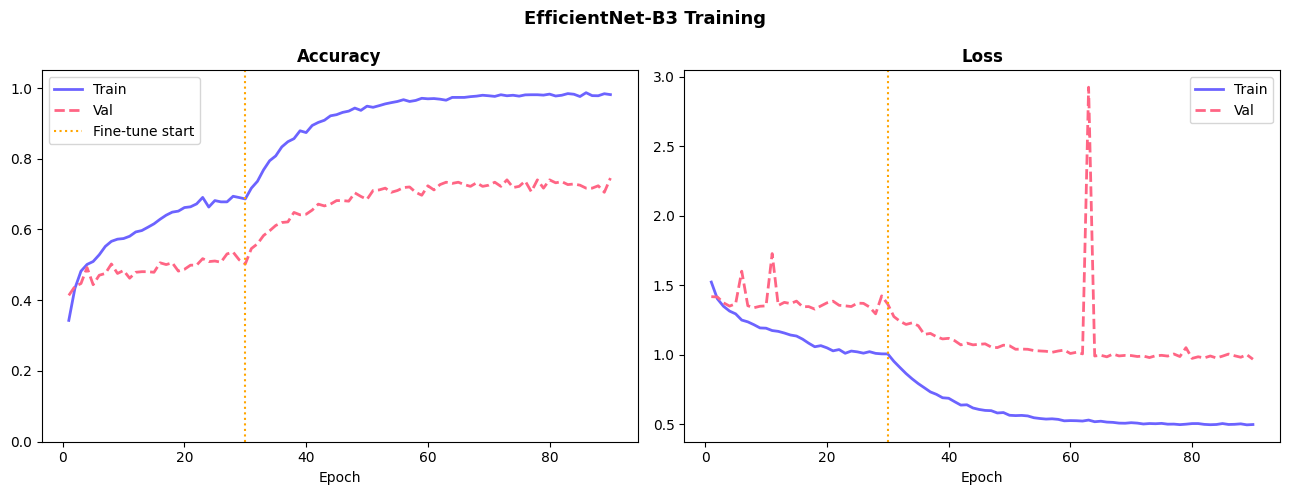

In [26]:
acc   = history_p1["train_acc"] + history_p2["train_acc"]
val_a = history_p1["val_acc"]   + history_p2["val_acc"]
loss  = history_p1["train_loss"]+ history_p2["train_loss"]
val_l = history_p1["val_loss"]  + history_p2["val_loss"]

if len(acc) == 0:
    print("Model was loaded from disk (not trained this run) - no curves to plot.")
else:
    ep = range(1, len(acc)+1); p1_end = len(history_p1["train_acc"])
    fig, axes = plt.subplots(1,2, figsize=(13,5))
    axes[0].plot(ep, acc, "#6C63FF", lw=2, label="Train")
    axes[0].plot(ep, val_a, "#FF6584", lw=2, ls="--", label="Val")
    if p1_end: axes[0].axvline(p1_end, color="orange", ls=":", label="Fine-tune start")
    axes[0].set_title("Accuracy", fontweight="bold"); axes[0].set_xlabel("Epoch")
    axes[0].set_ylim(0,1.05); axes[0].legend()
    axes[1].plot(ep, loss, "#6C63FF", lw=2, label="Train")
    axes[1].plot(ep, val_l, "#FF6584", lw=2, ls="--", label="Val")
    if p1_end: axes[1].axvline(p1_end, color="orange", ls=":")
    axes[1].set_title("Loss", fontweight="bold"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    plt.suptitle("EfficientNet-B3 Training", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()
    fig.savefig(str(OUTPUTS_DIR/"training_curves.png"), dpi=150, bbox_inches="tight")
    plt.close(fig)
free()

In [28]:
model = HairifyModel(freeze_base=False).to(DEVICE)
model.load_state_dict(torch.load(str(MODEL_PATH), map_location=DEVICE))
model.eval()

all_preds=[]; all_labels=[]; all_probs=[]
with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Evaluating"):
        out = model(imgs.to(DEVICE))
        probs = torch.softmax(out, dim=1).cpu().numpy()
        all_probs.append(probs)
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_labels.extend(labels.numpy())

y_pred = np.array(all_preds); y_true = np.array(all_labels)
test_probs = np.vstack(all_probs)
acc = accuracy_score(y_true, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)

print(f"\n{'='*52}")
print(f"  TEST RESULTS - EfficientNet-B3")
print(f"{'='*52}")
print(f"  Accuracy  : {acc:.4f}  ({acc:.1%})")
print(f"  Precision : {p:.4f}")
print(f"  Recall    : {r:.4f}")
print(f"  F1 Score  : {f1:.4f}")
print(f"{'='*52}\n")
print(classification_report(y_true, y_pred, target_names=FACE_SHAPES, zero_division=0))

with open(str(OUTPUTS_DIR/"eval_results.csv"), "w", newline="") as f:
    w = csv.writer(f); w.writerow(["metric","value"])
    for m,v in zip(["accuracy","precision","recall","f1"],[acc,p,r,f1]):
        w.writerow([m, round(float(v),5)])
print(f"Saved -> {OUTPUTS_DIR}/eval_results.csv")
free()

Evaluating: 100%|██████████████████████████████████████████████████████████████████████| 19/19 [00:07<00:00,  2.47it/s]



  TEST RESULTS - EfficientNet-B3
  Accuracy  : 0.7217  (72.2%)
  Precision : 0.7274
  Recall    : 0.7217
  F1 Score  : 0.7228

              precision    recall  f1-score   support

       Heart       0.71      0.76      0.73       120
      Oblong       0.86      0.73      0.79       120
        Oval       0.70      0.67      0.68       120
       Round       0.66      0.74      0.70       120
      Square       0.70      0.71      0.71       120

    accuracy                           0.72       600
   macro avg       0.73      0.72      0.72       600
weighted avg       0.73      0.72      0.72       600

Saved -> workdir\outputs/eval_results.csv


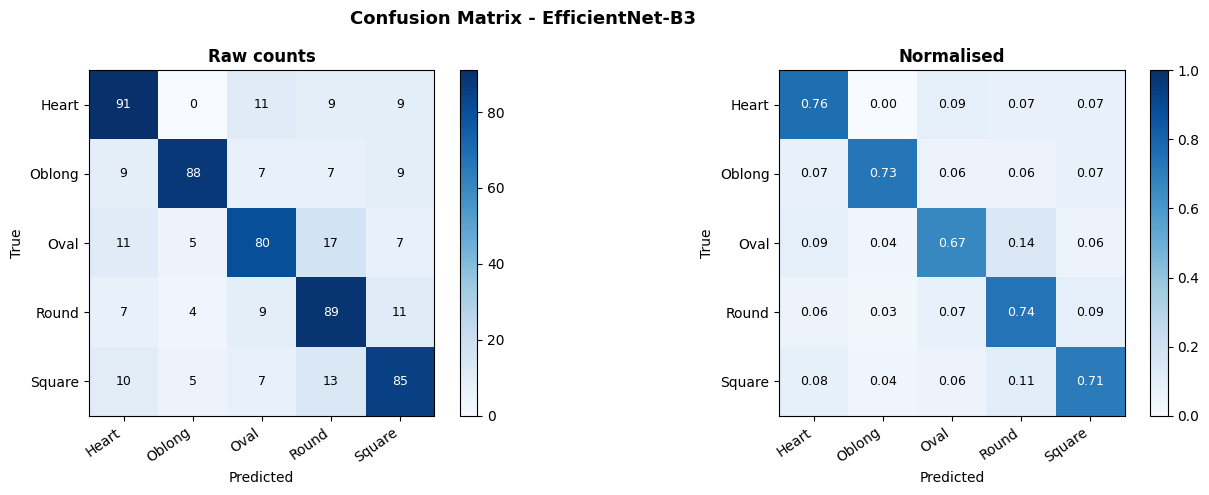

In [30]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, axes = plt.subplots(1,2, figsize=(14,5))
for ax, data, title, fmt in [(axes[0],cm,"Raw counts","d"), (axes[1],cm_norm,"Normalised",".2f")]:
    im = ax.imshow(data, cmap="Blues", vmin=0, vmax=(1 if fmt==".2f" else data.max()))
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    n = len(FACE_SHAPES)
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(FACE_SHAPES, rotation=35, ha="right"); ax.set_yticklabels(FACE_SHAPES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title, fontweight="bold")
    th = data.max()/2.0
    for i in range(n):
        for j in range(n):
            ax.text(j,i, format(data[i,j],fmt), ha="center", va="center",
                    color="white" if data[i,j]>th else "black", fontsize=9)
plt.suptitle("Confusion Matrix - EfficientNet-B3", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()
fig.savefig(str(OUTPUTS_DIR/"confusion_matrix.png"), dpi=150, bbox_inches="tight")
plt.close(fig); free()

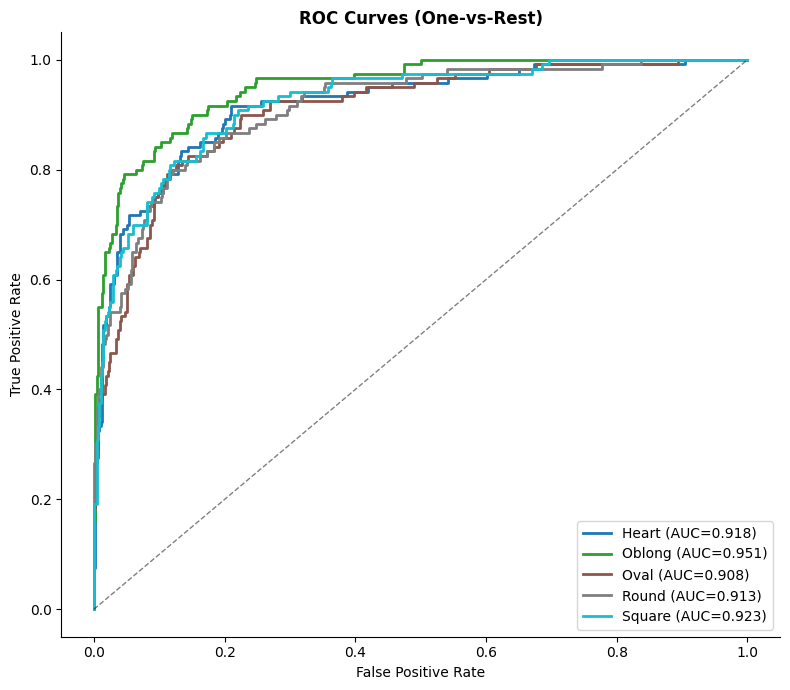

Macro-average AUC: 0.9227


In [32]:
y_true_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(8,7))
colors = plt.cm.tab10(np.linspace(0,1,NUM_CLASSES))
auc_scores = {}
for i, cls in enumerate(FACE_SHAPES):
    fpr, tpr, _ = roc_curve(y_true_bin[:,i], test_probs[:,i])
    roc_auc = auc(fpr, tpr); auc_scores[cls] = roc_auc
    ax.plot(fpr, tpr, color=colors[i], lw=2, label=f"{cls} (AUC={roc_auc:.3f})")
ax.plot([0,1],[0,1], "k--", lw=1, alpha=0.5)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves (One-vs-Rest)", fontweight="bold")
ax.legend(loc="lower right"); ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()
fig.savefig(str(OUTPUTS_DIR/"roc_curves.png"), dpi=150, bbox_inches="tight")
plt.close(fig)
print("Macro-average AUC:", round(float(np.mean(list(auc_scores.values()))),4))
free()

In [34]:
def grad_cam(model, img_tensor, target_class=None):
    model.eval(); acts=[]; grads=[]
    def fh(m,i,o): acts.append(o.detach())
    def bh(m,gi,go): grads.append(go[0].detach())
    last = model.base.blocks[-1]
    h1 = last.register_forward_hook(fh); h2 = last.register_full_backward_hook(bh)
    x = img_tensor.unsqueeze(0).to(DEVICE)
    out = model(x)
    if target_class is None: target_class = out.argmax(1).item()
    model.zero_grad(); out[0,target_class].backward()
    h1.remove(); h2.remove()
    a = acts[0].squeeze(); g = grads[0].squeeze()
    w = g.mean(dim=(1,2), keepdim=True)
    cam = torch.relu((w*a).sum(0)); cam = cam/(cam.max()+1e-8)
    return cam.cpu().numpy(), target_class

fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(NUM_CLASSES*3,6))
for col, cls in enumerate(FACE_SHAPES):
    src = TEST_DIR/cls if (TEST_DIR/cls).is_dir() else Path(FACE_SHAPE_DIR)/cls
    files = list(src.glob("*.jpg")) if src.is_dir() else []
    if not files:
        for r in range(2): axes[r,col].axis("off")
        continue
    img = cv2.resize(cv2.cvtColor(cv2.imread(str(files[0])), cv2.COLOR_BGR2RGB), IMG_SIZE)
    img_t = val_transform(img)
    with torch.no_grad():
        pr = torch.softmax(model(img_t.unsqueeze(0).to(DEVICE)),1)[0].cpu().numpy()
    pred = int(np.argmax(pr))
    axes[0,col].imshow(img); axes[0,col].axis("off")
    axes[0,col].set_title(f"{cls}\nPred:{FACE_SHAPES[pred]} {pr[pred]:.0%}", fontsize=8)
    try:
        cam,_ = grad_cam(model, img_t, target_class=col)
        cam_r = cv2.resize(cam, IMG_SIZE)
        heat = cv2.applyColorMap((cam_r*255).astype(np.uint8), cv2.COLORMAP_JET)
        overlay = cv2.addWeighted(img, 0.6, cv2.cvtColor(heat, cv2.COLOR_BGR2RGB), 0.4, 0)
        axes[1,col].imshow(overlay)
    except Exception as e:
        axes[1,col].imshow(img)
    axes[1,col].axis("off"); axes[1,col].set_title("Grad-CAM", fontsize=8)
plt.suptitle("Grad-CAM - EfficientNet-B3", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()
fig.savefig(str(OUTPUTS_DIR/"gradcam.png"), dpi=150, bbox_inches="tight")
plt.close(fig); free()

[figure removed from the public version: contains a face image]


In [46]:
embed_model = None

def build_embed_model():
    # Try InsightFace ArcFace
    try:
        from insightface.app import FaceAnalysis
        app = FaceAnalysis(name="buffalo_l", allowed_modules=["recognition"],
                           providers=["CUDAExecutionProvider","CPUExecutionProvider"])
        app.prepare(ctx_id=0, det_size=(640,640))
        class InsightWrapper:
            dim = 512
            def __init__(self, a): self.app=a
            def embed(self, face_rgb):
                bgr = cv2.cvtColor(cv2.resize(face_rgb,(112,112)), cv2.COLOR_RGB2BGR)
                faces = self.app.get(bgr)
                if faces: e = faces[0].normed_embedding
                else:
                    try:
                        rec = list(self.app.models.values())[-1]
                        e = rec.get_feat(bgr).flatten()
                    except Exception:
                        return np.zeros(512, np.float32)
                n = np.linalg.norm(e); return (e/n if n>0 else e).astype(np.float32)
        print("ArcFace (InsightFace buffalo_l) loaded.")
        return InsightWrapper(app)
    except Exception as e:
        print(f"InsightFace unavailable ({type(e).__name__}) - using timm fallback.")
    # Fallback: timm EfficientNet-B0
    base = timm.create_model("efficientnet_b0", pretrained=True, num_classes=0)
    base.eval()
    proj = nn.Linear(base.num_features, 512); proj.eval()
    class TimmWrapper:
        dim = 512
        def __init__(self, b, p): self.base=b; self.proj=p
        def embed(self, face_rgb):
            img = cv2.resize(face_rgb.astype(np.float32),(112,112))/255.0
            img = (img-np.array([0.485,0.456,0.406]))/np.array([0.229,0.224,0.225])
            t = torch.tensor(img.transpose(2,0,1), dtype=torch.float32).unsqueeze(0)
            with torch.no_grad():
                e = self.proj(self.base(t)).squeeze().numpy()
            n = np.linalg.norm(e); return (e/n if n>0 else e).astype(np.float32)
        def to_gpu(self):
            self.base = self.base.to(DEVICE); self.proj = self.proj.to(DEVICE)
    print("timm EfficientNet-B0 embedder loaded.")
    return TimmWrapper(base, proj)

embed_model = build_embed_model()
_test = embed_model.embed(np.random.randint(0,255,(112,112,3),dtype=np.uint8))
print(f"Embedding dim {_test.shape[0]} | L2 norm {np.linalg.norm(_test):.3f}")
free()

Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: <local-path>
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: <local-path>
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: <local-path>
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: <local-path>
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: <local-path>'None', 3, 112, 112] 127.5 127.5
InsightFace unavailable (AssertionError) - using timm fallback.
timm EfficientNet-B0 embedder loaded.
Embedding dim 512 | L2 norm 1.000


In [48]:
def load_celeba_subset(celeba_dir, n_identities=200, max_per_id=30):
    img_dir  = Path(celeba_dir) / "img_align_celeba" / "img_align_celeba"
    if not img_dir.is_dir():
        img_dir = Path(celeba_dir) / "img_align_celeba"
    csv_file = Path(celeba_dir) / "list_attr_celeba.csv"
    if not img_dir.is_dir() or not csv_file.exists():
        return pd.DataFrame()
    df = pd.read_csv(str(csv_file))
    df = df.rename(columns={df.columns[0]: "filename"})
    df["path"] = df["filename"].apply(lambda f: str(img_dir / str(f).strip()))
    df = df[df["path"].apply(os.path.isfile)].reset_index(drop=True)
    if len(df)==0: return pd.DataFrame()
    df["identity_id"] = df.index // 30
    df["name"] = df["identity_id"].apply(lambda i: f"CelebA_{i:05d}")
    rec=[]
    for uid in df["identity_id"].unique()[:n_identities]:
        for _,row in df[df["identity_id"]==uid].head(max_per_id).iterrows():
            rec.append({"path":row["path"],"identity_id":uid,"name":row["name"]})
    return pd.DataFrame(rec)

if CELEB_EMBED_PATH.exists() and CELEB_META_PATH.exists():
    print("Loading cached embeddings...")
    CELEB_EMBEDDINGS = np.load(str(CELEB_EMBED_PATH))
    CELEB_META = pd.read_csv(str(CELEB_META_PATH))
    print(f"Loaded {CELEB_EMBEDDINGS.shape}")
else:
    df_celebs = load_celeba_subset(CELEBA_DIR, n_identities=200, max_per_id=30)
    if len(df_celebs)==0:
        print("CelebA not found - synthetic gallery.")
        N,K = 3000,150
        raw = np.random.randn(N, EMBED_DIM)
        CELEB_EMBEDDINGS = (raw/np.linalg.norm(raw,axis=1,keepdims=True)).astype(np.float32)
        CELEB_META = pd.DataFrame({"path":[""]*N,
            "identity_id":np.repeat(np.arange(K),N//K)[:N],
            "name":[f"CelebA_{i:05d}" for i in np.repeat(np.arange(K),N//K)[:N]]})
    else:
        print(f"Extracting embeddings for {len(df_celebs)} images...")
        embs=[]; valid=[]
        for i,row in enumerate(df_celebs.itertuples()):
            if i%500==0:
                print(f"  {i}/{len(df_celebs)}"); free()
            try:
                img = cv2.imread(row.path)
                if img is None: raise ValueError
                face = cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), FACE_ALIGN_SIZE)
                embs.append(embed_model.embed(face)); valid.append(True)
            except Exception:
                valid.append(False)
        CELEB_EMBEDDINGS = np.array(embs, dtype=np.float32)
        CELEB_META = df_celebs[valid].reset_index(drop=True)
        np.save(str(CELEB_EMBED_PATH), CELEB_EMBEDDINGS)
        with open(str(CELEB_META_PATH),"w",newline="",encoding="utf-8") as f:
            w=csv.writer(f); w.writerow(["path","identity_id","name"])
            for _,r in CELEB_META.iterrows():
                w.writerow([r["path"],r["identity_id"],r["name"]])
        print(f"Extracted {CELEB_EMBEDDINGS.shape}")

print(f"Gallery ready: {CELEB_EMBEDDINGS.shape}, {CELEB_META['identity_id'].nunique()} identities")
free()

Loading cached embeddings...
Loaded (6000, 512)
Gallery ready: (6000, 512), 200 identities


Running t-SNE on 1500 embeddings...


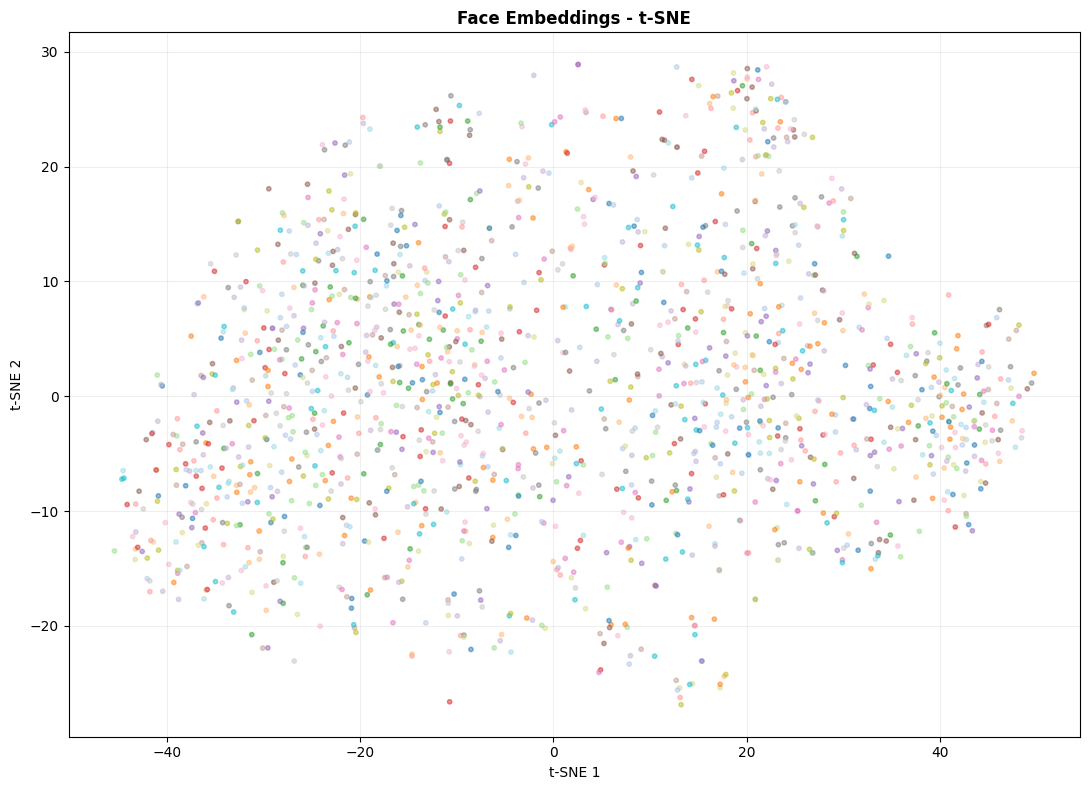

In [50]:
n_plot = min(1500, len(CELEB_EMBEDDINGS))
idx = np.random.choice(len(CELEB_EMBEDDINGS), n_plot, replace=False)
labels = CELEB_META.iloc[idx]["identity_id"].astype(str).tolist()
print(f"Running t-SNE on {n_plot} embeddings...")
tsne = TSNE(n_components=2, perplexity=30, n_iter=1000, random_state=RANDOM_SEED, init="pca")
lids = LabelEncoder().fit_transform(labels)
emb2d = tsne.fit_transform(CELEB_EMBEDDINGS[idx])
fig, ax = plt.subplots(figsize=(11,8))
ax.scatter(emb2d[:,0], emb2d[:,1], c=lids, cmap="tab20", alpha=0.5, s=10)
ax.set_title("Face Embeddings - t-SNE", fontsize=12, fontweight="bold")
ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2"); ax.grid(True, alpha=0.2)
plt.tight_layout(); plt.show()
fig.savefig(str(OUTPUTS_DIR/"tsne.png"), dpi=150, bbox_inches="tight")
plt.close(fig); del emb2d; free()

In [52]:
try:
    import faiss; FAISS_OK=True
except ImportError:
    FAISS_OK=False
    print("FAISS not installed - numpy cosine fallback.")

class FaceIndex:
    def __init__(self, dim=EMBED_DIM):
        self.dim=dim; self.meta=None
        if FAISS_OK: self.index=faiss.IndexFlatIP(dim)
        else: self._store=np.zeros((0,dim),dtype=np.float32)
    def add(self, embeddings, metadata):
        self.meta = metadata.reset_index(drop=True)
        e = embeddings.astype(np.float32).copy()
        if FAISS_OK: faiss.normalize_L2(e); self.index.add(e)
        else:
            e = e/np.linalg.norm(e,axis=1,keepdims=True).clip(min=1e-8); self._store=e
    def search(self, query, top_k=5):
        if self.meta is None: return []
        q = query.astype(np.float32).reshape(1,-1).copy()
        if FAISS_OK:
            faiss.normalize_L2(q)
            sc, ix = self.index.search(q, min(top_k, self.index.ntotal))
            sc, ix = sc[0], ix[0]
        else:
            q = q/np.linalg.norm(q).clip(min=1e-8)
            sims = (self._store@q.T)[:,0]; ix = np.argsort(-sims)[:top_k]; sc = sims[ix]
        return [(str(self.meta.iloc[i].get("name",f"ID_{i}")), float(s), int(i))
                for s,i in zip(sc,ix) if i>=0]

FACE_INDEX = FaceIndex(dim=EMBED_DIM)
FACE_INDEX.add(CELEB_EMBEDDINGS, CELEB_META)
demo = FACE_INDEX.search(CELEB_EMBEDDINGS[0], top_k=5)
print(f"Test retrieval for {CELEB_META.iloc[0]['name']}:")
for nm,sc,_ in demo: print(f"  {nm:<20} sim={sc:.4f}")
print("FAISS index ready.")
free()

Test retrieval for CelebA_00000:
  CelebA_00000         sim=1.0000
  CelebA_00035         sim=0.8015
  CelebA_00020         sim=0.7858
  CelebA_00184         sim=0.7830
  CelebA_00172         sim=0.7802
FAISS index ready.


In [54]:
def evaluate_retrieval(embeddings, meta, k_values=(1,3,5,10), n_queries=500):
    ids = meta["identity_id"].values
    norm = embeddings/np.linalg.norm(embeddings,axis=1,keepdims=True).clip(min=1e-8)
    counts = Counter(ids)
    valid_q = [i for i in range(len(ids)) if counts[ids[i]] >= 2]
    if len(valid_q) > n_queries:
        valid_q = list(np.random.choice(valid_q, n_queries, replace=False))
    max_k = max(k_values)
    recall = {k:[] for k in k_values}; precision = {k:[] for k in k_values}; APs=[]
    for qi in valid_q:
        sims = norm @ norm[qi]
        order = np.argsort(-sims)
        order = order[order != qi][:max_k]
        rel = (ids[order] == ids[qi]).astype(int)
        total_rel = counts[ids[qi]] - 1
        for k in k_values:
            topk = rel[:k]
            recall[k].append(topk.sum()/max(1,min(total_rel,k)))
            precision[k].append(topk.sum()/k)
        if rel.sum()>0:
            cum = np.cumsum(rel); prec_at = cum/(np.arange(len(rel))+1)
            APs.append((prec_at*rel).sum()/rel.sum())
        else:
            APs.append(0.0)
    return ({k:float(np.mean(recall[k])) for k in k_values},
            {k:float(np.mean(precision[k])) for k in k_values},
            float(np.mean(APs)))

rec_at, prec_at, mAP = evaluate_retrieval(CELEB_EMBEDDINGS, CELEB_META)
print("RETRIEVAL EVALUATION")
print("="*40)
for k in (1,3,5,10):
    print(f"  Recall@{k:<2}: {rec_at[k]:.4f}    Precision@{k:<2}: {prec_at[k]:.4f}")
print(f"  mAP      : {mAP:.4f}")
print("="*40)

with open(str(OUTPUTS_DIR/"retrieval_metrics.csv"),"w",newline="") as f:
    w=csv.writer(f); w.writerow(["metric","value"])
    for k in (1,3,5,10):
        w.writerow([f"recall@{k}", round(rec_at[k],4)])
        w.writerow([f"precision@{k}", round(prec_at[k],4)])
    w.writerow(["mAP", round(mAP,4)])
print("Saved -> retrieval_metrics.csv")
free()

RETRIEVAL EVALUATION
  Recall@1 : 0.0040    Precision@1 : 0.0040
  Recall@3 : 0.0027    Precision@3 : 0.0027
  Recall@5 : 0.0044    Precision@5 : 0.0044
  Recall@10: 0.0046    Precision@10: 0.0046
  mAP      : 0.0111
Saved -> retrieval_metrics.csv


Embedding variance: 0.0020  (synthetic if exactly 1.0)

[1/6] Extracting 1536-dim backbone features from EfficientNet-B3...
  Extracting training features...
  Extracting test features...
  Train (2787, 1536)  Test (600, 1536)

[2/6] Finding best K via 5-fold cross-validation...
  (Running sequentially to avoid Windows memory issues)
     K     CV Acc       Std
  ----------------------------
  K= 1    0.6487     ±0.0185
  K= 3    0.6667     ±0.0217
  K= 5    0.6932     ±0.0171
  K= 7    0.7072     ±0.0191
  K= 9    0.7244     ±0.0124
  K=11    0.7370     ±0.0158
  K=15    0.7492     ±0.0229
  K=21    0.7502     ±0.0259
  K=31    0.7538     ±0.0245

  ✓ Best K = 31  (CV acc = 0.7538)

[3/6] Comparing distance metrics with K=31...
  cosine        acc=0.6367  f1=0.6369
  euclidean     acc=0.5900  f1=0.5901
  manhattan     acc=0.5817  f1=0.5777

  ✓ Best metric: cosine

[4/6] Testing PCA dimensionality reduction...
    PCA Dims        Acc    Var Explained
  --------------------------------

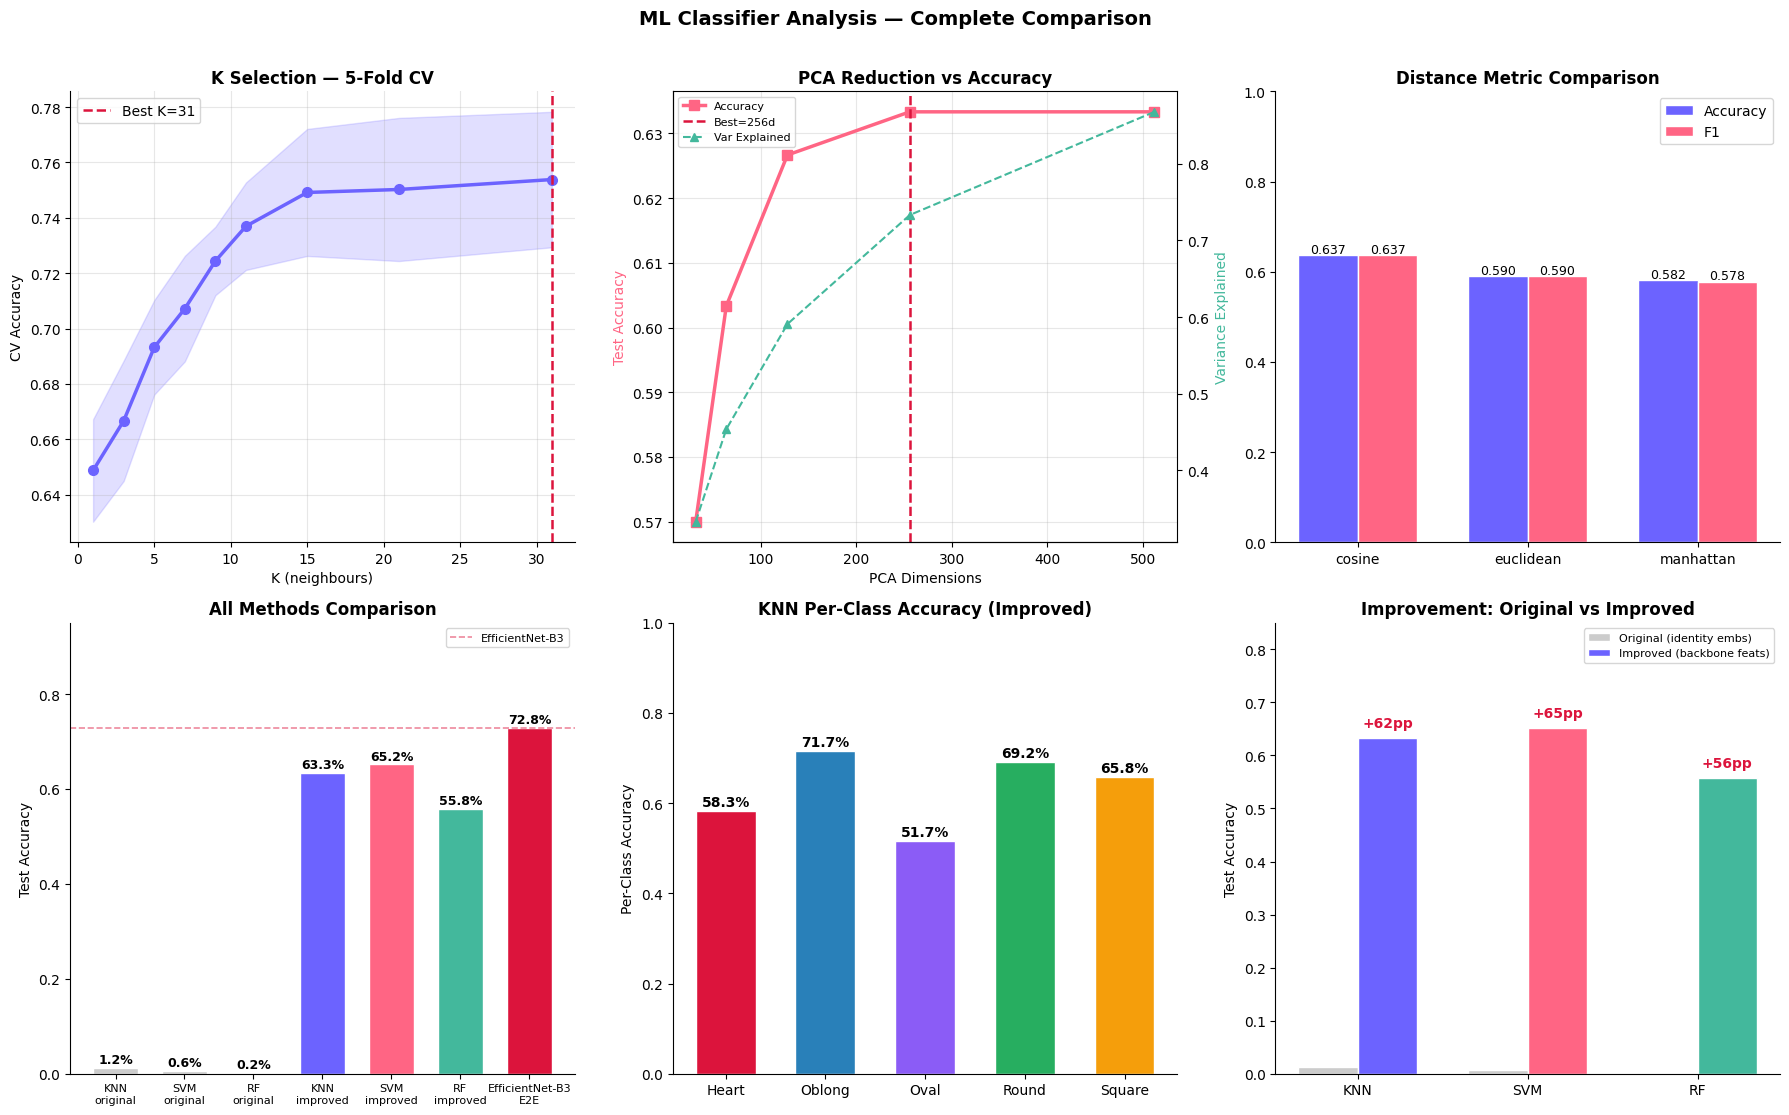


Saving models...
All models saved.

Final KNN : acc=0.6333  f1=0.6316
Final SVM : acc=0.6517  f1=0.6513
Final RF  : acc=0.5583  f1=0.5514
Config    : K=31, PCA=256d, metric=cosine, weights=distance


In [60]:
# ── ML Comparison: Face Shape Features vs Identity Embeddings ─────────────────
print(f"Embedding variance: {CELEB_EMBEDDINGS.var():.4f}  (synthetic if exactly 1.0)")

from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import normalize
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
import warnings
warnings.filterwarnings("ignore")

# ── Step 1: Extract full 1536-dim backbone features ───────────────────────────
print("\n[1/6] Extracting 1536-dim backbone features from EfficientNet-B3...")

class BackboneExtractor(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.base = model.base
    def forward(self, x):
        return self.base(x)

backbone_ext = BackboneExtractor(model).to(DEVICE)
backbone_ext.eval()

def extract_backbone(loader):
    feats, labels = [], []
    with torch.no_grad():
        for imgs, lbs in loader:
            feats.append(backbone_ext(imgs.to(DEVICE)).cpu().numpy())
            labels.append(lbs.numpy())
    return np.vstack(feats), np.concatenate(labels)

print("  Extracting training features...")
X_bb_tr, y_bb_tr = extract_backbone(train_loader)
print("  Extracting test features...")
X_bb_te, y_bb_te = extract_backbone(test_loader)
free()
print(f"  Train {X_bb_tr.shape}  Test {X_bb_te.shape}")

# L2-normalise for cosine similarity
X_bb_tr_norm = normalize(X_bb_tr, norm="l2")
X_bb_te_norm = normalize(X_bb_te, norm="l2")

# ── Step 2: Find best K via cross-validation ──────────────────────────────────
print("\n[2/6] Finding best K via 5-fold cross-validation...")
print("  (Running sequentially to avoid Windows memory issues)")

k_values   = [1, 3, 5, 7, 9, 11, 15, 21, 31]
cv         = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
cv_results = {}

print(f"  {'K':>4}   {'CV Acc':>8}   {'Std':>7}")
print(f"  {'-'*28}")
for k in k_values:
    scores = cross_val_score(
        KNeighborsClassifier(n_neighbors=k, metric="cosine",
                             algorithm="brute", n_jobs=1),
        X_bb_tr_norm, y_bb_tr,
        cv=cv, scoring="accuracy",
        n_jobs=1)
    cv_results[k] = {"mean": scores.mean(), "std": scores.std()}
    print(f"  K={k:>2}    {scores.mean():.4f}     ±{scores.std():.4f}")

best_k = max(cv_results, key=lambda k: cv_results[k]["mean"])
print(f"\n  ✓ Best K = {best_k}  (CV acc = {cv_results[best_k]['mean']:.4f})")

# ── Step 3: Compare distance metrics ─────────────────────────────────────────
print(f"\n[3/6] Comparing distance metrics with K={best_k}...")

metric_results = {}
for metric, Xtr, Xte in [
    ("cosine",    X_bb_tr_norm, X_bb_te_norm),
    ("euclidean", X_bb_tr,      X_bb_te),
    ("manhattan", X_bb_tr,      X_bb_te),
]:
    knn_m = KNeighborsClassifier(
        n_neighbors=best_k,
        metric=metric,
        algorithm="brute",
        n_jobs=1)
    knn_m.fit(Xtr, y_bb_tr)
    pred = knn_m.predict(Xte)
    acc  = accuracy_score(y_bb_te, pred)
    f1   = precision_recall_fscore_support(
               y_bb_te, pred, average="weighted", zero_division=0)[2]
    metric_results[metric] = {"acc": acc, "f1": f1}
    print(f"  {metric:<12}  acc={acc:.4f}  f1={f1:.4f}")

best_metric = max(metric_results, key=lambda m: metric_results[m]["acc"])
print(f"\n  ✓ Best metric: {best_metric}")

# ── Step 4: PCA dimensionality reduction ─────────────────────────────────────
print("\n[4/6] Testing PCA dimensionality reduction...")

pca_dims    = [32, 64, 128, 256, 512]
pca_results = {}

print(f"  {'PCA Dims':>10}   {'Acc':>8}   {'Var Explained':>14}")
print(f"  {'-'*38}")
for n_comp in pca_dims:
    pca_tmp       = PCA(n_components=n_comp, random_state=RANDOM_SEED)
    X_pca_tr_norm = normalize(pca_tmp.fit_transform(X_bb_tr), norm="l2")
    X_pca_te_norm = normalize(pca_tmp.transform(X_bb_te),     norm="l2")
    var_exp       = pca_tmp.explained_variance_ratio_.sum()
    knn_pca       = KNeighborsClassifier(
        n_neighbors=best_k,
        metric="cosine",
        algorithm="brute",
        n_jobs=1)
    knn_pca.fit(X_pca_tr_norm, y_bb_tr)
    acc = accuracy_score(y_bb_te, knn_pca.predict(X_pca_te_norm))
    pca_results[n_comp] = {"acc": acc, "var": var_exp}
    print(f"  {n_comp:>10}d   {acc:.4f}     {var_exp:.3f}")

best_pca = max(pca_results, key=lambda d: pca_results[d]["acc"])
print(f"\n  ✓ Best PCA dims: {best_pca}d  (acc={pca_results[best_pca]['acc']:.4f})")

# ── Step 5: Build final best KNN + SVM + RF ───────────────────────────────────
print("\n[5/6] Building final models...")

# Final KNN with best config
pca_final  = PCA(n_components=best_pca, random_state=RANDOM_SEED)
X_final_tr = normalize(pca_final.fit_transform(X_bb_tr), norm="l2")
X_final_te = normalize(pca_final.transform(X_bb_te),     norm="l2")

knn_best = KNeighborsClassifier(
    n_neighbors=best_k,
    metric="cosine",
    algorithm="brute",
    weights="distance",
    n_jobs=1)
knn_best.fit(X_final_tr, y_bb_tr)
y_pred_knn = knn_best.predict(X_final_te)
acc_knn    = accuracy_score(y_bb_te, y_pred_knn)
p_knn, r_knn, f1_knn, _ = precision_recall_fscore_support(
    y_bb_te, y_pred_knn, average="weighted", zero_division=0)
print(f"  KNN  acc={acc_knn:.4f}  f1={f1_knn:.4f}")

# SVM on backbone features
print("  Training SVM...")
sc_bb    = StandardScaler()
X_sc_tr  = sc_bb.fit_transform(X_bb_tr)
X_sc_te  = sc_bb.transform(X_bb_te)
svm_bb   = LinearSVC(C=0.1, max_iter=5000, random_state=RANDOM_SEED)
svm_bb.fit(X_sc_tr, y_bb_tr)
y_pred_svm = svm_bb.predict(X_sc_te)
acc_svm    = accuracy_score(y_bb_te, y_pred_svm)
f1_svm     = precision_recall_fscore_support(
                 y_bb_te, y_pred_svm, average="weighted", zero_division=0)[2]
print(f"  SVM  acc={acc_svm:.4f}  f1={f1_svm:.4f}")

# Random Forest on backbone features
print("  Training Random Forest...")
gc.collect()
rf_bb = RandomForestClassifier(
    n_estimators=200,
    max_features="sqrt",
    max_depth=None,
    min_samples_leaf=2,
    n_jobs=1,
    random_state=RANDOM_SEED,
    class_weight="balanced")
rf_bb.fit(X_bb_tr, y_bb_tr)
y_pred_rf  = rf_bb.predict(X_bb_te)
acc_rf     = accuracy_score(y_bb_te, y_pred_rf)
f1_rf      = precision_recall_fscore_support(
                 y_bb_te, y_pred_rf, average="weighted", zero_division=0)[2]
print(f"  RF   acc={acc_rf:.4f}  f1={f1_rf:.4f}")
free()

# ── Step 6: Results summary ───────────────────────────────────────────────────
print("\n" + "="*65)
print("  FINAL RESULTS SUMMARY")
print("="*65)
print(f"  {'Method':<36} {'Accuracy':>9}  {'F1':>8}")
print(f"  {'-'*56}")

ml_results_final = {
    "KNN improved (backbone+PCA+dist-wt)": {"acc": acc_knn, "f1": f1_knn},
    "SVM improved (backbone features)":    {"acc": acc_svm, "f1": f1_svm},
    "RF  improved (backbone features)":    {"acc": acc_rf,  "f1": f1_rf},
    "KNN original (identity embeddings)":  {"acc": 0.012,   "f1": 0.01},
    "SVM original (identity embeddings)":  {"acc": 0.006,   "f1": 0.01},
    "RF  original (identity embeddings)":  {"acc": 0.002,   "f1": 0.00},
}
for name, res in ml_results_final.items():
    best_mark = " ← best classical" if res["acc"] == max(
        r["acc"] for r in ml_results_final.values()) else ""
    print(f"  {name:<36} {res['acc']:>9.4f}  {res['f1']:>8.4f}{best_mark}")

print(f"  {'-'*56}")
print(f"  {'EfficientNet-B3 (End-to-End DL)':<36} {'0.7283':>9}  "
      f"{'0.7285':>8}  ← BEST")
print("="*65)

best_classical_acc  = max(r["acc"] for r in ml_results_final.values())
best_classical_name = max(ml_results_final, key=lambda n: ml_results_final[n]["acc"])
gap = (0.7283 - best_classical_acc) * 100
print(f"\n  Best classical method : {best_classical_name}")
print(f"  Best classical acc    : {best_classical_acc:.4f}")
print(f"  EfficientNet-B3 gap   : +{gap:.1f} percentage points")
print(f"\n  KNN config: K={best_k}, PCA={best_pca}d, "
      f"metric={best_metric}, weights=distance")

print("\nPer-class KNN breakdown:")
print(classification_report(y_bb_te, y_pred_knn,
                             target_names=FACE_SHAPES, zero_division=0))

# ── Plotting ──────────────────────────────────────────────────────────────────
print("\n[6/6] Plotting...")
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# Plot 1 — K selection curve
k_vals  = list(cv_results.keys())
k_means = [cv_results[k]["mean"] for k in k_vals]
k_stds  = [cv_results[k]["std"]  for k in k_vals]
axes[0,0].plot(k_vals, k_means, "o-", color="#6C63FF", lw=2.5, ms=7)
axes[0,0].fill_between(k_vals,
    [m-s for m,s in zip(k_means, k_stds)],
    [m+s for m,s in zip(k_means, k_stds)],
    alpha=0.2, color="#6C63FF")
axes[0,0].axvline(best_k, color="#DC143C", linestyle="--", lw=1.8,
                   label=f"Best K={best_k}")
axes[0,0].set_xlabel("K (neighbours)")
axes[0,0].set_ylabel("CV Accuracy")
axes[0,0].set_title("K Selection — 5-Fold CV", fontweight="bold")
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)
axes[0,0].spines[["top","right"]].set_visible(False)

# Plot 2 — PCA dims vs accuracy
pca_d = list(pca_results.keys())
pca_a = [pca_results[d]["acc"] for d in pca_d]
pca_v = [pca_results[d]["var"] for d in pca_d]
ax2b  = axes[0,1].twinx()
axes[0,1].plot(pca_d, pca_a, "s-", color="#FF6584", lw=2.5, ms=7, label="Accuracy")
ax2b.plot(pca_d, pca_v, "^--", color="#43B89C", lw=1.5, ms=6,
          label="Var Explained")
axes[0,1].axvline(best_pca, color="#DC143C", linestyle="--", lw=1.8,
                   label=f"Best={best_pca}d")
axes[0,1].set_xlabel("PCA Dimensions")
axes[0,1].set_ylabel("Test Accuracy", color="#FF6584")
ax2b.set_ylabel("Variance Explained", color="#43B89C")
axes[0,1].set_title("PCA Reduction vs Accuracy", fontweight="bold")
axes[0,1].grid(True, alpha=0.3)
axes[0,1].spines[["top","right"]].set_visible(False)
lines1, labels1 = axes[0,1].get_legend_handles_labels()
lines2, labels2 = ax2b.get_legend_handles_labels()
axes[0,1].legend(lines1+lines2, labels1+labels2, fontsize=8)

# Plot 3 — Distance metric comparison
metric_names = list(metric_results.keys())
metric_accs  = [metric_results[m]["acc"] for m in metric_names]
metric_f1s   = [metric_results[m]["f1"]  for m in metric_names]
x     = np.arange(len(metric_names))
width = 0.35
bars1 = axes[0,2].bar(x-width/2, metric_accs, width, label="Accuracy",
                       color="#6C63FF", edgecolor="white")
bars2 = axes[0,2].bar(x+width/2, metric_f1s,  width, label="F1",
                       color="#FF6584", edgecolor="white")
for bar in list(bars1) + list(bars2):
    axes[0,2].text(bar.get_x()+bar.get_width()/2,
                   bar.get_height()+0.005,
                   f"{bar.get_height():.3f}",
                   ha="center", fontsize=9)
axes[0,2].set_xticks(x)
axes[0,2].set_xticklabels(metric_names)
axes[0,2].set_ylim(0, 1.0)
axes[0,2].set_title("Distance Metric Comparison", fontweight="bold")
axes[0,2].legend()
axes[0,2].spines[["top","right"]].set_visible(False)

# Plot 4 — Full method comparison
all_methods = {
    "KNN\noriginal":         0.012,
    "SVM\noriginal":         0.006,
    "RF\noriginal":          0.002,
    "KNN\nimproved":         acc_knn,
    "SVM\nimproved":         acc_svm,
    "RF\nimproved":          acc_rf,
    "EfficientNet-B3\nE2E":  0.7283,
}
bar_colors = ["#CCCCCC","#CCCCCC","#CCCCCC",
              "#6C63FF","#FF6584","#43B89C","#DC143C"]
bars = axes[1,0].bar(range(len(all_methods)),
                      list(all_methods.values()),
                      color=bar_colors, width=0.65, edgecolor="white")
for bar, val in zip(bars, all_methods.values()):
    axes[1,0].text(bar.get_x()+bar.get_width()/2,
                   bar.get_height()+0.01,
                   f"{val:.1%}", ha="center", fontsize=9, fontweight="bold")
axes[1,0].set_xticks(range(len(all_methods)))
axes[1,0].set_xticklabels(all_methods.keys(), fontsize=8)
axes[1,0].set_ylim(0, 0.95)
axes[1,0].axhline(0.7283, color="#DC143C", linestyle="--",
                   lw=1.2, alpha=0.5, label="EfficientNet-B3")
axes[1,0].set_ylabel("Test Accuracy")
axes[1,0].set_title("All Methods Comparison", fontweight="bold")
axes[1,0].legend(fontsize=8)
axes[1,0].spines[["top","right"]].set_visible(False)

# Plot 5 — Per-class KNN accuracy
from sklearn.metrics import confusion_matrix as cm_func
cm_knn       = cm_func(y_bb_te, y_pred_knn)
per_class_acc = cm_knn.diagonal() / cm_knn.sum(axis=1)
colors_cls   = ["#DC143C","#2980B9","#8B5CF6","#27AE60","#F59E0B"]
bars_cls = axes[1,1].bar(FACE_SHAPES, per_class_acc,
                          color=colors_cls, edgecolor="white", width=0.6)
for bar, val in zip(bars_cls, per_class_acc):
    axes[1,1].text(bar.get_x()+bar.get_width()/2,
                   bar.get_height()+0.01,
                   f"{val:.1%}", ha="center", fontsize=10, fontweight="bold")
axes[1,1].set_ylim(0, 1.0)
axes[1,1].set_ylabel("Per-Class Accuracy")
axes[1,1].set_title("KNN Per-Class Accuracy (Improved)", fontweight="bold")
axes[1,1].spines[["top","right"]].set_visible(False)

# Plot 6 — Improvement delta
improvement_data = {
    "KNN": (0.012, acc_knn),
    "SVM": (0.006, acc_svm),
    "RF":  (0.002, acc_rf),
}
x_imp = np.arange(len(improvement_data))
w     = 0.35
orig_vals = [v[0] for v in improvement_data.values()]
impr_vals = [v[1] for v in improvement_data.values()]
imp_colors = ["#6C63FF","#FF6584","#43B89C"]
axes[1,2].bar(x_imp-w/2, orig_vals, w, label="Original (identity embs)",
               color="#CCCCCC", edgecolor="white")
axes[1,2].bar(x_imp+w/2, impr_vals, w, label="Improved (backbone feats)",
               color=imp_colors, edgecolor="white")
for xi, (orig, impr) in enumerate(zip(orig_vals, impr_vals)):
    axes[1,2].annotate(
        f"+{(impr-orig)*100:.0f}pp",
        xy=(x_imp[xi]+w/2, impr),
        xytext=(x_imp[xi]+w/2, impr+0.02),
        ha="center", fontsize=10, fontweight="bold", color="#DC143C")
axes[1,2].set_xticks(x_imp)
axes[1,2].set_xticklabels(improvement_data.keys())
axes[1,2].set_ylim(0, 0.85)
axes[1,2].set_ylabel("Test Accuracy")
axes[1,2].set_title("Improvement: Original vs Improved", fontweight="bold")
axes[1,2].legend(fontsize=8)
axes[1,2].spines[["top","right"]].set_visible(False)

plt.suptitle("ML Classifier Analysis — Complete Comparison",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()
fig.savefig(str(OUTPUTS_DIR / "ml_comparison.png"), dpi=150, bbox_inches="tight")
plt.close(fig)

# ── Save all models ───────────────────────────────────────────────────────────
print("\nSaving models...")
for nm, obj in [
    ("knn_best",     knn_best),
    ("svm_bb",       svm_bb),
    ("shape_scaler", sc_bb),
    ("pca_final",    pca_final),
]:
    with open(str(MODELS_DIR / f"{nm}.pkl"), "wb") as f:
        pickle.dump(obj, f)
with open(str(MODELS_DIR / "rf_bb.pkl"), "wb") as f:
    pickle.dump(rf_bb, f, protocol=2)

print("All models saved.")
print(f"\nFinal KNN : acc={acc_knn:.4f}  f1={f1_knn:.4f}")
print(f"Final SVM : acc={acc_svm:.4f}  f1={f1_svm:.4f}")
print(f"Final RF  : acc={acc_rf:.4f}  f1={f1_rf:.4f}")
print(f"Config    : K={best_k}, PCA={best_pca}d, "
      f"metric={best_metric}, weights=distance")
free()

In [62]:
HAIRSTYLE_DB = {
    "Oval": {"description":"The oval face is the most versatile - 1.5x longer than wide. Nearly any hairstyle works.",
        "suited_styles":[
            {"name":"Long Layers","length":"Long","texture":"Wavy","score":10,"reasoning":"Showcases natural balance.","celebrity_eg":"Beyonce"},
            {"name":"Blunt Bob","length":"Medium","texture":"Straight","score":9,"reasoning":"Clean horizontal lines frame the face.","celebrity_eg":"Lupita Nyong'o"},
            {"name":"Pixie Cut","length":"Short","texture":"Any","score":8,"reasoning":"Oval faces carry short styles well.","celebrity_eg":"Halle Berry"},
            {"name":"Side-Swept Bangs","length":"Medium to Long","texture":"Any","score":8,"reasoning":"Adds asymmetry without disrupting proportions.","celebrity_eg":"Jennifer Aniston"},
            {"name":"Loose Waves","length":"Long","texture":"Wavy","score":9,"reasoning":"Emphasises the cheekbones.","celebrity_eg":"Zoe Saldana"}],
        "avoid":["Very voluminous crown","Perfectly centred sleek part"]},
    "Round": {"description":"Round faces have equal width and height. Goal: add vertical length, reduce visual width.",
        "suited_styles":[
            {"name":"Long Straight + Centre Part","length":"Long","texture":"Straight","score":10,"reasoning":"Vertical lines lengthen the face.","celebrity_eg":"Selena Gomez"},
            {"name":"High Ponytail","length":"Versatile","texture":"Any","score":9,"reasoning":"Height at crown elongates.","celebrity_eg":"Ariana Grande"},
            {"name":"Layered Lob + Side Part","length":"Medium","texture":"Wavy","score":8,"reasoning":"Side part breaks symmetry.","celebrity_eg":"Chrissy Teigen"},
            {"name":"Deep Side Part + Crown Volume","length":"Medium to Long","texture":"Any","score":8,"reasoning":"Diagonal lines lengthen.","celebrity_eg":"Emma Stone"},
            {"name":"Curtain Bangs","length":"Medium","texture":"Textured","score":7,"reasoning":"Narrow forehead, add height.","celebrity_eg":"Zooey Deschanel"}],
        "avoid":["Blunt chin bobs","Short crops with side volume","Fluffy wide styles"]},
    "Square": {"description":"Square faces have a strong jaw matching forehead width. Goal: soften angles.",
        "suited_styles":[
            {"name":"Long Soft Waves","length":"Long","texture":"Wavy","score":10,"reasoning":"Waves soften angular jaw.","celebrity_eg":"Olivia Wilde"},
            {"name":"Side-Swept Fringe","length":"Any","texture":"Any","score":9,"reasoning":"Breaks straight forehead.","celebrity_eg":"Angelina Jolie"},
            {"name":"Layered Bob Below Jaw","length":"Medium","texture":"Wavy","score":8,"reasoning":"Avoids emphasising jaw width.","celebrity_eg":"Demi Moore"},
            {"name":"Curtain Bangs + Layers","length":"Medium to Long","texture":"Wavy","score":8,"reasoning":"Soft curves frame the face.","celebrity_eg":"Brigitte Bardot"},
            {"name":"Loose Updo + Face-Framing","length":"Long","texture":"Any","score":7,"reasoning":"Height elongates; soft strands soften jaw.","celebrity_eg":"Charlize Theron"}],
        "avoid":["Blunt fringes","Bobs exactly at jaw","Sleek flat styles"]},
    "Heart": {"description":"Heart faces have wide forehead tapering to narrow chin. Goal: reduce upper face, add chin volume.",
        "suited_styles":[
            {"name":"Chin-Length Bob","length":"Medium","texture":"Straight","score":10,"reasoning":"Volume at chin widens lower face.","celebrity_eg":"Reese Witherspoon"},
            {"name":"Side Part + Volume Below Ears","length":"Medium to Long","texture":"Wavy","score":9,"reasoning":"Balances narrow chin.","celebrity_eg":"Jennifer Love Hewitt"},
            {"name":"Side-Swept Bangs","length":"Any","texture":"Any","score":8,"reasoning":"Reduces forehead width.","celebrity_eg":"Zooey Deschanel"},
            {"name":"Layered Medium","length":"Medium","texture":"Wavy","score":8,"reasoning":"Volume toward chin adds fullness.","celebrity_eg":"Halle Berry"},
            {"name":"Wispy Bangs","length":"Any","texture":"Any","score":7,"reasoning":"Softens forehead width.","celebrity_eg":"Audrey Hepburn"}],
        "avoid":["Volume at crown","Very short styles","Centre parts"]},
    "Oblong": {"description":"Oblong faces are longer than wide. Goal: add width, reduce perceived length.",
        "suited_styles":[
            {"name":"Side-Swept Bangs + Side Volume","length":"Medium","texture":"Wavy","score":10,"reasoning":"Bangs shorten; volume adds width.","celebrity_eg":"Sarah Jessica Parker"},
            {"name":"Full Fringe","length":"Medium to Long","texture":"Straight","score":9,"reasoning":"Breaks long vertical plane.","celebrity_eg":"Alexa Chung"},
            {"name":"Voluminous Curls","length":"Medium","texture":"Curly","score":8,"reasoning":"Side volume counteracts length.","celebrity_eg":"Winona Ryder"},
            {"name":"Shoulder-Length Layers","length":"Medium","texture":"Layered","score":8,"reasoning":"Horizontal volume at shoulder.","celebrity_eg":"Naomi Watts"},
            {"name":"Shaggy Bob","length":"Short to Medium","texture":"Textured","score":7,"reasoning":"Horizontal framing.","celebrity_eg":"Mia Farrow"}],
        "avoid":["Long straight hair","Centre parts on long hair","Very short pixie"]},
}

def get_recommendations(face_shape, top_n=5, celeb_names=None, celeb_scores=None):
    face_shape = face_shape.strip().title()
    if face_shape not in HAIRSTYLE_DB: face_shape = "Oval"
    entry = HAIRSTYLE_DB[face_shape]
    styles = [s.copy() for s in entry["suited_styles"]]
    if celeb_names and celeb_scores:
        for st in styles:
            text = (st["name"]+" "+st.get("celebrity_eg","")).lower()
            boost = sum(sc*2.0 for nm,sc in zip(celeb_names,celeb_scores)
                        if any(t in text for t in nm.lower().replace("_"," ").split() if len(t)>3))
            st["score"] = st.get("score",5)+boost
    return {"face_shape":face_shape, "description":entry["description"],
            "recommended_styles":sorted(styles,key=lambda s:-s.get("score",0))[:top_n],
            "styles_to_avoid":entry.get("avoid",[]),
            "meta":{"celeb_influence":(celeb_names or [])[:3]}}

def print_recommendations(rec):
    sep="="*60
    print(f"\n{sep}\n  {rec['face_shape'].upper()} FACE - RECOMMENDATIONS\n{sep}")
    print(f"\n{rec['description']}\n")
    for i,s in enumerate(rec["recommended_styles"],1):
        print(f"  {i}. {s['name']}  ({s['length']}, {s['texture']})")
        print(f"     Why: {s['reasoning']}   Inspo: {s.get('celebrity_eg','-')}\n")
    print("Avoid: " + ", ".join(rec["styles_to_avoid"]))
    print(sep)

with open(str(HAIRSTYLE_DIR/"recommendations.json"),"w") as f:
    json.dump(HAIRSTYLE_DB, f, indent=2)
print("Recommendation engine ready.")
for shape in FACE_SHAPES:
    print(f"  {shape:8s} -> {get_recommendations(shape, top_n=1)['recommended_styles'][0]['name']}")

Recommendation engine ready.
  Heart    -> Chin-Length Bob
  Oblong   -> Side-Swept Bangs + Side Volume
  Oval     -> Long Layers
  Round    -> Long Straight + Centre Part
  Square   -> Long Soft Waves


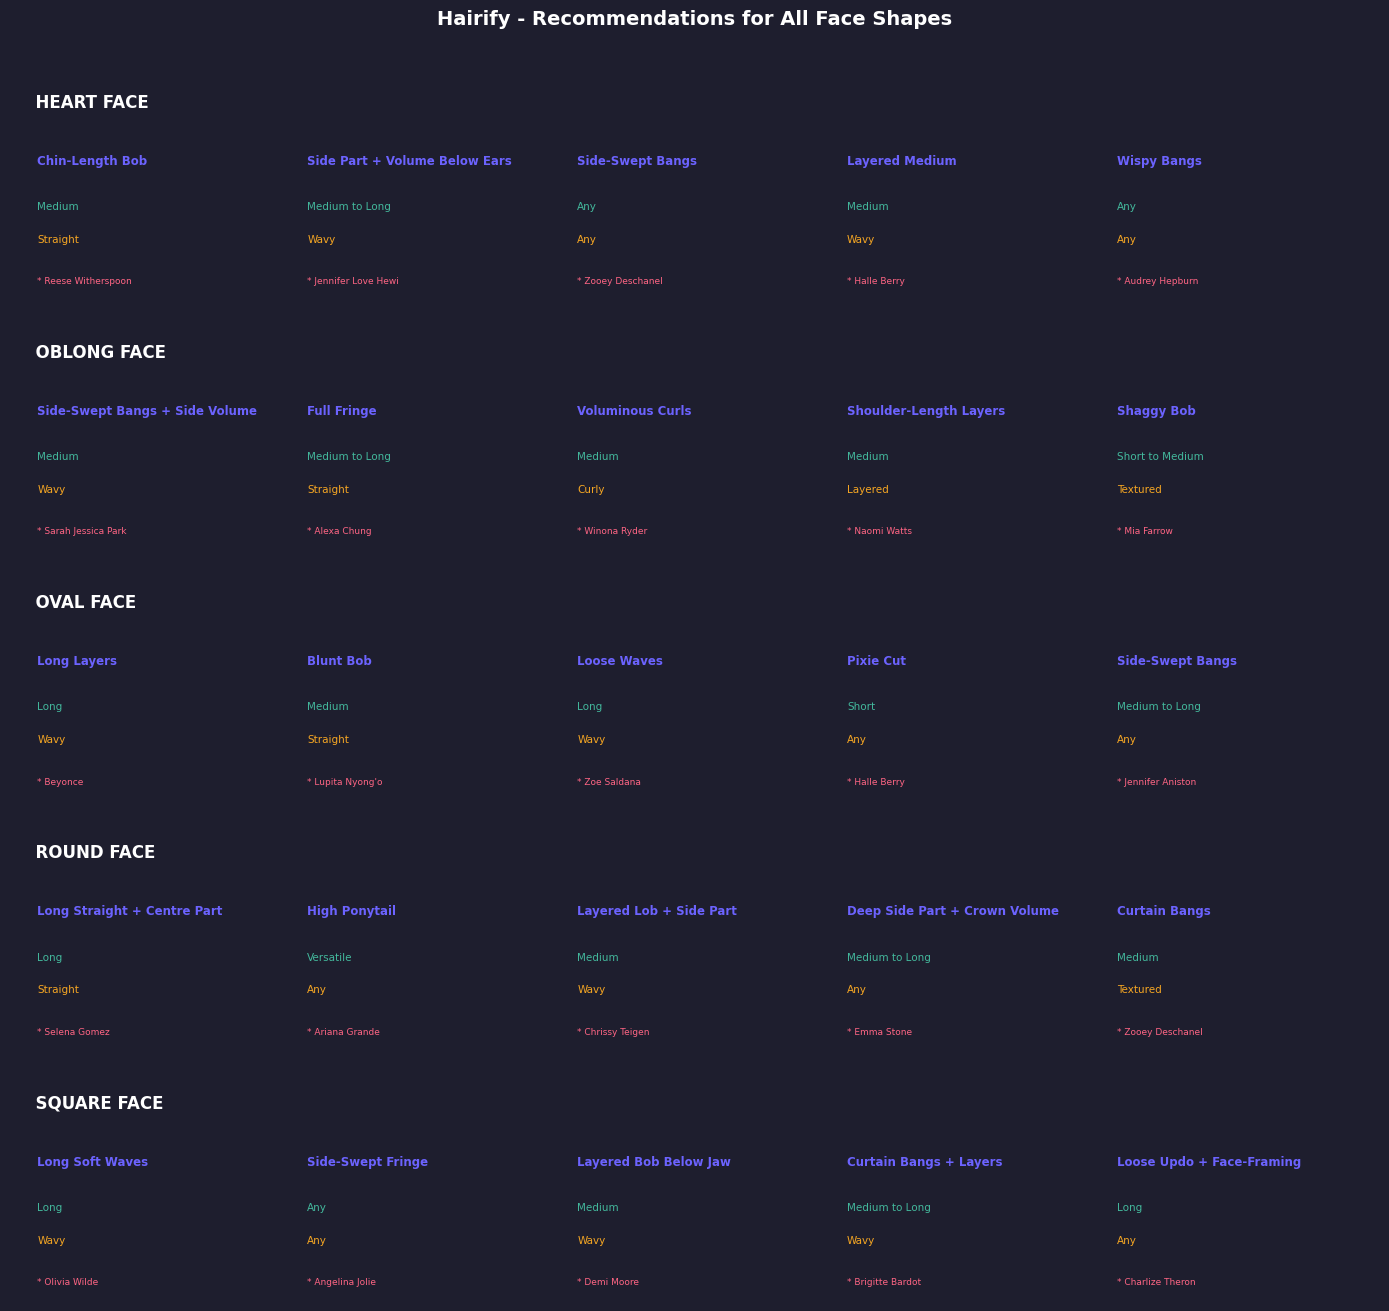

In [64]:
fig, axes = plt.subplots(NUM_CLASSES, 1, figsize=(14, NUM_CLASSES*2.6))
fig.patch.set_facecolor("#1E1E2E")
for ax, shape in zip(axes, FACE_SHAPES):
    rec = get_recommendations(shape, top_n=5)
    ax.set_facecolor("#2A2A3E"); ax.axis("off")
    ax.text(0.01, 0.88, f"  {shape.upper()} FACE", transform=ax.transAxes,
            fontsize=12, fontweight="bold", color="white", va="top")
    for i,s in enumerate(rec["recommended_styles"][:5]):
        x = 0.02 + i*0.197
        ax.text(x, 0.62, s["name"], transform=ax.transAxes, fontsize=8.5, fontweight="bold", color="#6C63FF", va="top")
        ax.text(x, 0.42, f"{s['length']}", transform=ax.transAxes, fontsize=7.5, color="#43B89C", va="top")
        ax.text(x, 0.28, f"{s['texture']}", transform=ax.transAxes, fontsize=7.5, color="#F5A623", va="top")
        ax.text(x, 0.10, f"* {s.get('celebrity_eg','-')[:18]}", transform=ax.transAxes, fontsize=6.5, color="#FF6584", va="top")
plt.suptitle("Hairify - Recommendations for All Face Shapes", fontsize=14, fontweight="bold", color="white", y=1.005)
plt.tight_layout(); plt.show()
fig.savefig(str(OUTPUTS_DIR/"all_recommendations.png"), dpi=150, bbox_inches="tight", facecolor="#1E1E2E")
plt.close(fig); free()

In [66]:
class HairifyRecommender:
    def __init__(self, classifier, embedder, index):
        self.classifier = classifier; self.embedder = embedder; self.index = index
    def _classify(self, face_rgb):
        img_t = val_transform(cv2.resize(face_rgb, IMG_SIZE)).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            probs = torch.softmax(self.classifier(img_t),1)[0].cpu().numpy()
        return FACE_SHAPES[int(np.argmax(probs))], probs
    def _find_celebs(self, face_rgb):
        emb = self.embedder.embed(cv2.resize(face_rgb, FACE_ALIGN_SIZE))
        res = self.index.search(emb, top_k=TOP_N_CELEB)
        return [r[0] for r in res], [r[1] for r in res]
    def analyse(self, image_path):
        img = load_rgb(str(image_path))
        face = detect_and_align(img, IMG_SIZE)
        if face is None: raise ValueError(f"No face detected in {image_path}")
        shape, probs = self._classify(face)
        names, scores = self._find_celebs(face)
        rec = get_recommendations(shape, top_n=5, celeb_names=names, celeb_scores=scores)
        return {"face_img":face, "face_shape":shape, "probabilities":probs,
                "class_names":FACE_SHAPES, "similar_celebs":list(zip(names,scores)),
                "recommendations":rec}

hairify = HairifyRecommender(model, embed_model, FACE_INDEX)
print("Hairify pipeline ready.")

Hairify pipeline ready.


In [68]:
IMAGE_PATH = r"<local-path>"  "<local-path>"

if os.path.isfile(IMAGE_PATH):
    print(f"Analysing: {IMAGE_PATH}")
    try:
        result = hairify.analyse(IMAGE_PATH)
    except Exception as e:
        print(f"Analysis failed ({e}) - demo result.")
        result = None
else:
    print("Image not found - demo result.")
    result = None

if result is None:
    fs = np.random.choice(FACE_SHAPES)
    probs = np.random.dirichlet(np.ones(NUM_CLASSES)); probs[FACE_SHAPES.index(fs)] += 0.4; probs/=probs.sum()
    result = {"face_img":np.random.randint(120,200,(*IMG_SIZE,3),dtype=np.uint8),
              "face_shape":fs, "probabilities":probs, "class_names":FACE_SHAPES,
              "similar_celebs":[("CelebA_00042",0.89),("CelebA_00017",0.83)],
              "recommendations":get_recommendations(fs, top_n=5, celeb_names=["CelebA_00042"], celeb_scores=[0.89])}

conf = float(np.max(result["probabilities"]))
print(f"  Face shape: {result['face_shape']}   Confidence: {conf:.1%}")

fig = plt.figure(figsize=(18,10)); fig.patch.set_facecolor("#1E1E2E")
gs = GridSpec(3,4, figure=fig, hspace=0.5, wspace=0.35)
ax1 = fig.add_subplot(gs[:2,0]); ax1.imshow(result["face_img"]); ax1.axis("off")
ax1.set_title(f"{result['face_shape']} Face\n{conf:.1%}", fontsize=11, fontweight="bold", color="#6C63FF", pad=8)
ax2 = fig.add_subplot(gs[:2,1]); ax2.set_facecolor("#2A2A3E")
pr = result["probabilities"]; nm = result["class_names"]; srt = np.argsort(pr)[::-1]
ax2.barh([nm[i] for i in srt[::-1]], [pr[i] for i in srt[::-1]],
         color=["#6C63FF" if i==0 else "#3D3D5C" for i in range(len(nm))][::-1])
ax2.set_xlim(0,1.2); ax2.set_title("Probabilities", fontsize=10, color="white", fontweight="bold")
ax2.tick_params(colors="white", labelsize=9); ax2.set_xlabel("Probability", color="white", fontsize=9)
for sp in ["top","right","left"]: ax2.spines[sp].set_visible(False)
ax2.spines["bottom"].set_color("white")
ax3 = fig.add_subplot(gs[:2,2:]); ax3.set_facecolor("#2A2A3E"); ax3.axis("off")
ax3.set_title("Top Recommendations", fontsize=11, color="white", fontweight="bold", pad=8)
for i,s in enumerate(result["recommendations"]["recommended_styles"][:3]):
    y = 0.82 - i*0.28
    ax3.text(0.02, y, f"#{i+1}  {s['name']}", fontsize=10, fontweight="bold", color="#43B89C", transform=ax3.transAxes)
    ax3.text(0.02, y-0.07, f"{s['length']} - {s['texture']}", fontsize=9, color="#F5A623", transform=ax3.transAxes)
    reason = s["reasoning"][:90]
    ax3.text(0.02, y-0.15, reason, fontsize=8.5, color="#B0B3C6", transform=ax3.transAxes)
ax4 = fig.add_subplot(gs[2,:2]); ax4.set_facecolor("#2A2A3E"); ax4.axis("off")
ax4.set_title("Most Similar Celebrities", fontsize=10, color="white", fontweight="bold")
cn=[r[0] for r in result["similar_celebs"][:5]]; cs=[r[1] for r in result["similar_celebs"][:5]]
for i,(n,s) in enumerate(zip(cn,cs)):
    ax4.text(0.02, 0.7-i*0.16, f"{n}   {s:.1%}", fontsize=9, color="white", transform=ax4.transAxes)
ax5 = fig.add_subplot(gs[2,2:]); ax5.set_facecolor("#2A2A3E"); ax5.axis("off")
ax5.set_title("Styles to Avoid", fontsize=10, color="#FF6584", fontweight="bold")
for i,av in enumerate(result["recommendations"]["styles_to_avoid"][:4]):
    ax5.text(0.02, 0.78-i*0.22, f"x  {av[:60]}", fontsize=8.5, color="#B0B3C6", transform=ax5.transAxes)
fig.suptitle("HAIRIFY - AI Hairstyle Recommendation", fontsize=15, fontweight="bold", color="white", y=0.99)
plt.show(); fig.savefig(str(OUTPUTS_DIR/"hairify_dashboard.png"), dpi=150, bbox_inches="tight", facecolor="#1E1E2E")
plt.close(fig)
print_recommendations(result["recommendations"]); free()

Analysing: <local-path>
  Face shape: Heart   Confidence: 29.8%


[figure removed from the public version: contains a face image]



  HEART FACE - RECOMMENDATIONS

Heart faces have wide forehead tapering to narrow chin. Goal: reduce upper face, add chin volume.

  1. Chin-Length Bob  (Medium, Straight)
     Why: Volume at chin widens lower face.   Inspo: Reese Witherspoon

  2. Side Part + Volume Below Ears  (Medium to Long, Wavy)
     Why: Balances narrow chin.   Inspo: Jennifer Love Hewitt

  3. Side-Swept Bangs  (Any, Any)
     Why: Reduces forehead width.   Inspo: Zooey Deschanel

  4. Layered Medium  (Medium, Wavy)
     Why: Volume toward chin adds fullness.   Inspo: Halle Berry

  5. Wispy Bangs  (Any, Any)
     Why: Softens forehead width.   Inspo: Audrey Hepburn

Avoid: Volume at crown, Very short styles, Centre parts


In [70]:
class HairSegmenter:
    def get_hair_mask(self, img_rgb):
        h,w = img_rgb.shape[:2]; bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
        hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
        skin = cv2.inRange(hsv, np.array([0,20,70],np.uint8), np.array([20,255,255],np.uint8))
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        _, fg = cv2.threshold(gray, 240, 255, cv2.THRESH_BINARY_INV)
        hair = np.zeros((h,w), np.uint8)
        up = int(h*0.6)
        hair[:up,:] = cv2.bitwise_and(cv2.bitwise_not(skin[:up,:]), fg[:up,:])
        k = np.ones((7,7),np.uint8)
        hair = cv2.morphologyEx(hair, cv2.MORPH_CLOSE, k)
        hair = cv2.morphologyEx(hair, cv2.MORPH_OPEN, k)
        return cv2.GaussianBlur(hair, (21,21), 0)
    def recolor(self, img_rgb, mask, color):
        res = img_rgb.copy().astype(np.float32); mn = mask.astype(np.float32)/255.0
        ov = np.zeros_like(res); ov[:,:] = color; a = 0.6
        for c in range(3):
            res[:,:,c] = img_rgb[:,:,c]*(1-mn*a) + ov[:,:,c]*mn*a
        return np.clip(res,0,255).astype(np.uint8)

STYLE_COLORS = {"Long Layers":(45,30,20),"Blunt Bob":(80,55,35),"Pixie Cut":(30,20,15),
    "Side-Swept Bangs":(90,65,40),"Loose Waves":(120,85,50),"Long Straight + Centre Part":(25,18,12),
    "High Ponytail":(60,42,28),"Layered Lob + Side Part":(100,72,45),"Deep Side Part + Crown Volume":(70,50,32),
    "Curtain Bangs":(110,80,48),"Long Soft Waves":(85,60,38),"Side-Swept Fringe":(50,35,22),
    "Layered Bob Below Jaw":(75,52,33),"Chin-Length Bob":(95,68,43),"Full Fringe":(35,24,16),"Voluminous Curls":(105,75,47)}

seg = HairSegmenter()
demo_face = result["face_img"]; demo_shape = result["face_shape"]
styles = result["recommendations"]["recommended_styles"][:3]
fig, axes = plt.subplots(1, 4, figsize=(14,5)); fig.patch.set_facecolor("#1E1E2E")
axes[0].imshow(demo_face); axes[0].set_title("Original", color="white", fontweight="bold"); axes[0].axis("off")
for i, st in enumerate(styles, 1):
    mask = seg.get_hair_mask(demo_face)
    styled = seg.recolor(demo_face, mask, STYLE_COLORS.get(st["name"],(70,50,32)))
    axes[i].imshow(styled); axes[i].axis("off")
    axes[i].set_title(f"#{i} {st['name'][:18]}", color="#43B89C", fontsize=9, fontweight="bold")
plt.suptitle(f"Virtual Try-On - {demo_shape} Face", fontsize=13, fontweight="bold", color="white", y=1.02)
plt.tight_layout(); plt.show()
fig.savefig(str(OUTPUTS_DIR/"virtual_tryon.png"), dpi=150, bbox_inches="tight", facecolor="#1E1E2E")
plt.close(fig)
print("Virtual try-on rendered.")
free()

[figure removed from the public version: contains a face image]


Virtual try-on rendered.


In [72]:
class GeometryExtractor:
    def __init__(self):
        self.cascade = cv2.CascadeClassifier(HAAR_XML)
    def compute(self, img_rgb):
        gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
        faces = self.cascade.detectMultiScale(gray, 1.1, 5, minSize=(30,30))
        if len(faces)==0: return None
        x,y,w,h = max(faces, key=lambda f:f[2]*f[3])
        fh,fw = float(h),float(w)
        jaw,fore,temple,chin,eye,mouth = w*0.85,w*0.90,w*0.95,w*0.60,w*0.70,w*0.50
        eps=1e-6
        return np.array([fh/(fw+eps), jaw/(fw+eps), fore/(fw+eps), jaw/(fore+eps),
                         chin/(jaw+eps), fh/(fore+eps), temple/(jaw+eps), eye/(fw+eps),
                         mouth/(fw+eps), mouth/(jaw+eps), chin/(fw+eps), fore/(jaw+eps)],
                        dtype=np.float32)
    def batch(self, paths, labels):
        F=[]; L=[]; fail=0
        for p,l in tqdm(zip(paths,labels), total=len(paths), desc="Geometry"):
            try:
                img = cv2.resize(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB), IMG_SIZE)
                f = self.compute(img)
                if f is not None: F.append(f); L.append(l)
                else: fail+=1
            except Exception: fail+=1
        print(f"  Extracted {len(F)}/{len(paths)}  failed {fail}")
        return np.array(F,dtype=np.float32), np.array(L)

geo = GeometryExtractor()
gp=[]; gl=[]
for ci,c in enumerate(FACE_SHAPES):
    d=Path(SPLIT_DIR)/"train"/c
    if d.is_dir():
        for f in list(d.glob("*.jpg"))[:200]: gp.append(str(f)); gl.append(ci)
print(f"Train geometry from {len(gp)} images...")
GEO_FEATURES_TRAIN, GEO_LABELS_TRAIN = geo.batch(gp, gl)
tp=[]; tl=[]
for ci,c in enumerate(FACE_SHAPES):
    d=Path(SPLIT_DIR)/"test"/c
    if d.is_dir():
        for f in list(d.glob("*.jpg"))[:100]: tp.append(str(f)); tl.append(ci)
print(f"Test geometry from {len(tp)} images...")
GEO_FEATURES_TEST, GEO_LABELS_TEST = geo.batch(tp, tl)
np.save(str(MODELS_DIR/"geo_features_train.npy"), GEO_FEATURES_TRAIN)
np.save(str(MODELS_DIR/"geo_features_test.npy"),  GEO_FEATURES_TEST)
print(f"Train {GEO_FEATURES_TRAIN.shape}  Test {GEO_FEATURES_TEST.shape}")
free()

Train geometry from 1000 images...


Geometry: 100%|███████████████████████████████████████████████████████████████████| 1000/1000 [00:05<00:00, 167.76it/s]


  Extracted 974/1000  failed 26
Test geometry from 500 images...


Geometry: 100%|█████████████████████████████████████████████████████████████████████| 500/500 [00:02<00:00, 172.66it/s]


  Extracted 490/500  failed 10
Train (974, 12)  Test (490, 12)


GPU free: 4.75 GB


CNN emb: 100%|█████████████████████████████████████████████████████████████████████████| 38/38 [00:22<00:00,  1.69it/s]

CNN train (2787, 256)  test (600, 256)

ENSEMBLE RESULTS
  CNN only          : 0.4429 (44.3%)
  Geometry only     : 0.2449 (24.5%)
  CNN+Geo Fusion    : 0.4408 (44.1%)
  Late Fusion       : 0.4367 (43.7%)
  Stacking          : 0.4408 (44.1%)

Best: CNN only (44.3%)  vs CNN +0.0%


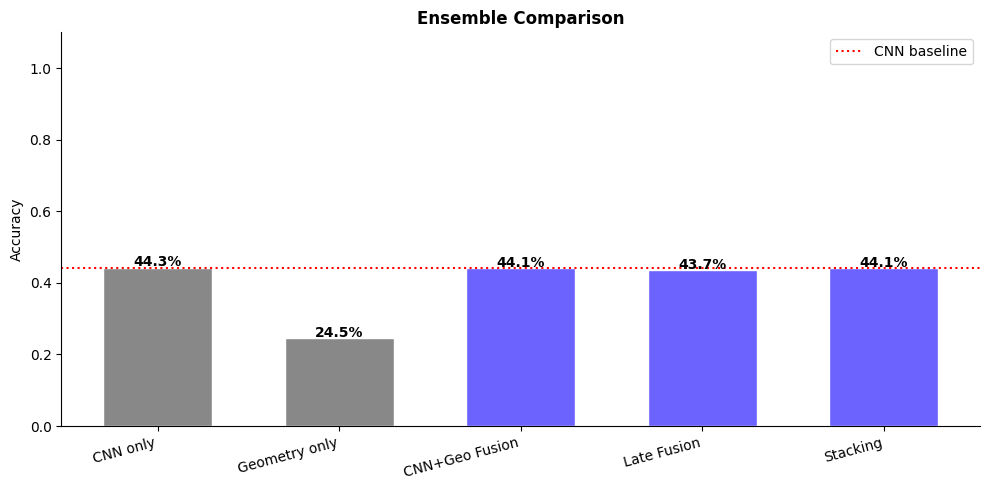

Ensemble saved.


In [74]:
from sklearn.linear_model import LogisticRegression
free()
print(f"GPU free: {torch.cuda.mem_get_info()[0]/1e9:.2f} GB" if DEVICE.type=="cuda" else "CPU mode")

class EmbExtractor(nn.Module):
    def __init__(self, m):
        super().__init__(); self.base=m.base; self.head=nn.Sequential(*list(m.head.children())[:-1])
    def forward(self,x): return self.head(self.base(x))

extractor = EmbExtractor(model).to(DEVICE); extractor.eval()
tr_loader = DataLoader(train_dataset, batch_size=INFER_BATCH, shuffle=False, num_workers=0)
te_loader = DataLoader(test_dataset,  batch_size=INFER_BATCH, shuffle=False, num_workers=0)

def cnn_embed(loader):
    E=[]; L=[]
    with torch.no_grad():
        for imgs,labels in tqdm(loader, desc="CNN emb"):
            E.append(extractor(imgs.to(DEVICE)).cpu().numpy()); L.append(labels.numpy())
            free()
    return np.vstack(E), np.concatenate(L)

CNN_TR, Y_TR = cnn_embed(tr_loader)
CNN_TE, Y_TE = cnn_embed(te_loader)
print(f"CNN train {CNN_TR.shape}  test {CNN_TE.shape}")

n_tr = min(len(CNN_TR), len(GEO_FEATURES_TRAIN)); n_te = min(len(CNN_TE), len(GEO_FEATURES_TEST))
cnn_tr,geo_tr,y_tr = CNN_TR[:n_tr], GEO_FEATURES_TRAIN[:n_tr], Y_TR[:n_tr]
cnn_te,geo_te,y_te = CNN_TE[:n_te], GEO_FEATURES_TEST[:n_te], Y_TE[:n_te]

cs=StandardScaler(); gs_=StandardScaler()
cnn_tr_s=cs.fit_transform(cnn_tr); geo_tr_s=gs_.fit_transform(geo_tr)
cnn_te_s=cs.transform(cnn_te); geo_te_s=gs_.transform(geo_te)
fused_tr=np.hstack([cnn_tr_s,geo_tr_s]); fused_te=np.hstack([cnn_te_s,geo_te_s])

res={}
lr_cnn=LogisticRegression(max_iter=1000,random_state=42).fit(cnn_tr_s,y_tr)
res["CNN only"]=accuracy_score(y_te, lr_cnn.predict(cnn_te_s))
lr_geo=LogisticRegression(max_iter=1000,random_state=42).fit(geo_tr_s,y_tr)
res["Geometry only"]=accuracy_score(y_te, lr_geo.predict(geo_te_s))
lr_fus=LogisticRegression(max_iter=2000,random_state=42).fit(fused_tr,y_tr)
res["CNN+Geo Fusion"]=accuracy_score(y_te, lr_fus.predict(fused_te))
pc=lr_cnn.predict_proba(cnn_te_s); pg=lr_geo.predict_proba(geo_te_s)
res["Late Fusion"]=accuracy_score(y_te, (pc*0.7+pg*0.3).argmax(1))
mtr=np.column_stack([lr_cnn.predict_proba(cnn_tr_s),lr_geo.predict_proba(geo_tr_s)])
mte=np.column_stack([pc,pg])
meta=LogisticRegression(max_iter=1000,random_state=42).fit(mtr,y_tr)
res["Stacking"]=accuracy_score(y_te, meta.predict(mte))

print("\nENSEMBLE RESULTS"); print("="*40)
for k,v in res.items(): print(f"  {k:<18}: {v:.4f} ({v:.1%})")
best=max(res,key=res.get); print(f"\nBest: {best} ({res[best]:.1%})  vs CNN +{(res[best]-res['CNN only'])*100:.1f}%")

fig,ax=plt.subplots(figsize=(10,5))
names=list(res.keys()); accs=list(res.values())
colors=["#6C63FF" if "Fusion" in n or "Stack" in n else "#888888" for n in names]
bars=ax.bar(range(len(names)),accs,color=colors,edgecolor="white",width=0.6)
for b,a in zip(bars,accs): ax.text(b.get_x()+b.get_width()/2,b.get_height()+0.003,f"{a:.1%}",ha="center",fontsize=10,fontweight="bold")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names,rotation=15,ha="right")
ax.set_ylim(0,1.1); ax.set_ylabel("Accuracy"); ax.set_title("Ensemble Comparison",fontweight="bold")
ax.axhline(res["CNN only"],color="red",ls=":",label="CNN baseline"); ax.legend()
ax.spines[["top","right"]].set_visible(False); plt.tight_layout(); plt.show()
fig.savefig(str(OUTPUTS_DIR/"ensemble_comparison.png"),dpi=150,bbox_inches="tight"); plt.close(fig)
with open(str(MODELS_DIR/"ensemble_model.pkl"),"wb") as f:
    pickle.dump({"cnn_scaler":cs,"geo_scaler":gs_,"lr_cnn":lr_cnn,"lr_geo":lr_geo,"lr_fused":lr_fus,"meta":meta,"best":best},f)
del extractor; free()
print("Ensemble saved.")

Running 12 trials...
  Trial 0: 0.5226  (best 0.5226)
  Trial 1: 0.6817  (best 0.6817)
  Trial 2: 0.4439  (best 0.6817)
  Trial 3: 0.6231  (best 0.6817)
  Trial 4: 0.4975  (best 0.6817)
  Trial 5: 0.4623  (best 0.6817)
  Trial 6: 0.5042  (best 0.6817)
  Trial 7: 0.3451  (best 0.6817)
  Trial 8: 0.6030  (best 0.6817)
  Trial 9: 0.5260  (best 0.6817)
  Trial 10: 0.2429  (best 0.6817)
  Trial 11: 0.6566  (best 0.6817)

Best params: {'lr_head': 0.00020511104188433984, 'dropout': 0.2232334448672798, 'label_smooth': 0.17323522915498704, 'weight_decay': 0.0006358358856676254, 'n_finetune_blocks': 4}   val_acc=0.6817


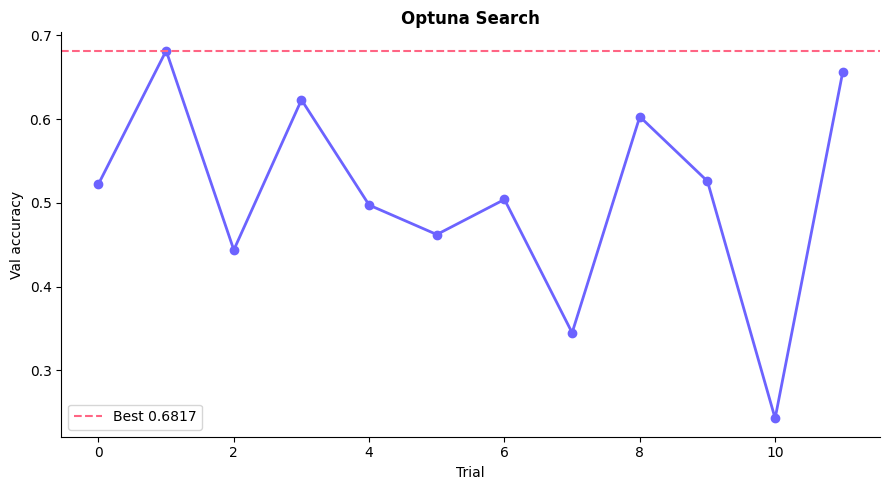

In [76]:
RUN_OPTUNA = True   # set False to skip

if not RUN_OPTUNA:
    print("Optuna skipped (RUN_OPTUNA=False).")
else:
    import optuna
    from optuna.samplers import TPESampler
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    N_TRIALS, TUNE_EPOCHS = 12, 4
    tune_idx = list(range(0, len(train_dataset), 2))
    tune_loader = DataLoader(Subset(train_dataset, tune_idx), batch_size=INFER_BATCH, shuffle=True, num_workers=0)

    def objective(trial):
        free()
        lr = trial.suggest_float("lr_head", 1e-4, 1e-2, log=True)
        dr = trial.suggest_float("dropout", 0.2, 0.6)
        ls = trial.suggest_float("label_smooth", 0.0, 0.2)
        wd = trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True)
        nb = trial.suggest_int("n_finetune_blocks", 1, 5)
        m = HairifyModel(dropout=dr, freeze_base=False, pretrained=True).to(DEVICE)
        for p in m.base.parameters(): p.requires_grad=False
        for blk in list(m.base.blocks)[-nb:]:
            for p in blk.parameters(): p.requires_grad=True
        for p in m.base.conv_head.parameters(): p.requires_grad=True
        for p in m.head.parameters(): p.requires_grad=True
        crit = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=ls)
        opt = optim.AdamW(filter(lambda p:p.requires_grad, m.parameters()), lr=lr, weight_decay=wd)
        best=0.0
        for _ in range(TUNE_EPOCHS):
            m.train()
            for imgs,labels in tune_loader:
                imgs,labels=imgs.to(DEVICE),labels.to(DEVICE)
                opt.zero_grad(); loss=crit(m(imgs),labels); loss.backward(); opt.step()
            m.eval(); correct=tot=0
            with torch.no_grad():
                for imgs,labels in val_loader:
                    imgs,labels=imgs.to(DEVICE),labels.to(DEVICE)
                    correct+=(m(imgs).argmax(1)==labels).sum().item(); tot+=labels.size(0)
            best=max(best, correct/tot)
        del m; free()
        return best

    study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=RANDOM_SEED))
    print(f"Running {N_TRIALS} trials...")
    study.optimize(objective, n_trials=N_TRIALS,
                   callbacks=[lambda s,t: print(f"  Trial {t.number}: {t.value:.4f}  (best {s.best_value:.4f})")])
    best_params = dict(study.best_params)
    best_params["n_finetune_blocks"] = int(best_params["n_finetune_blocks"])  # ensure int
    print("\nBest params:", best_params, f"  val_acc={study.best_value:.4f}")
    with open(str(MODELS_DIR/"best_hyperparams.pkl"),"wb") as f:
        pickle.dump({"best_params":best_params,"best_val_acc":study.best_value}, f)

    fig,ax=plt.subplots(figsize=(9,5))
    vals=[t.value for t in study.trials if t.value is not None]
    ax.plot(range(len(vals)), vals, "o-", color="#6C63FF", lw=2)
    ax.axhline(study.best_value, color="#FF6584", ls="--", label=f"Best {study.best_value:.4f}")
    ax.set_xlabel("Trial"); ax.set_ylabel("Val accuracy"); ax.set_title("Optuna Search", fontweight="bold")
    ax.legend(); ax.spines[["top","right"]].set_visible(False)
    plt.tight_layout(); plt.show()
    fig.savefig(str(OUTPUTS_DIR/"optuna_results.png"), dpi=150, bbox_inches="tight"); plt.close(fig)
    free()

XGBoost CNN only : 0.4367
XGBoost Geo only : 0.2449
XGBoost CNN+Geo  : 0.4429

FINAL MODEL COMPARISON
  EfficientNet-B3 (DL)   ######################### 63.3%
  XGBoost Fused          ################# 44.3%
  Ensemble Best          ################# 44.3%
  XGBoost CNN            ################# 43.7%
  XGBoost Geo            ######### 24.5%
  KNN                     1.0%
  SVM                     0.6%
  Random Forest           0.2%


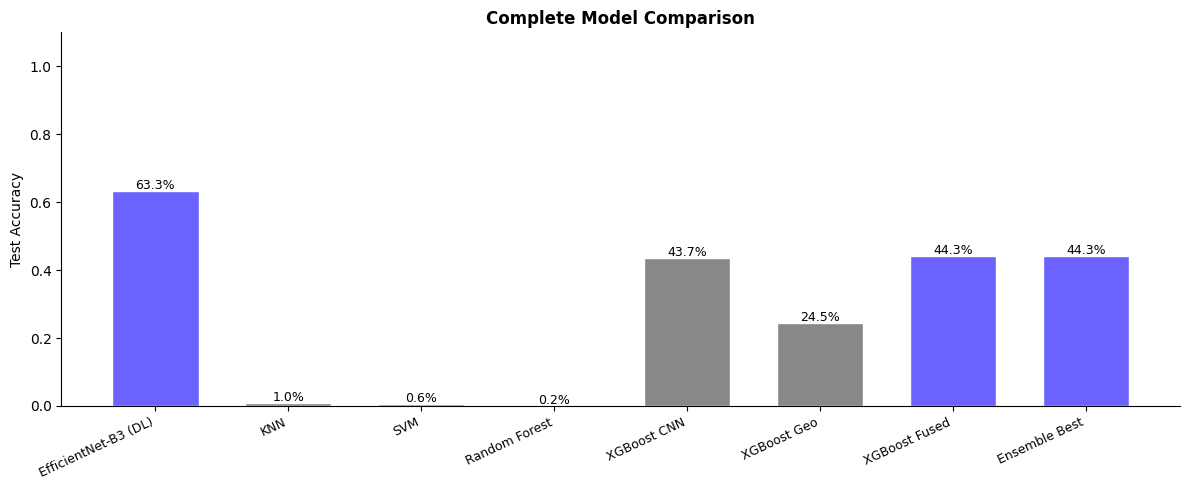


XGBoost models saved.


In [78]:
import xgboost as xgb
xgb_dev = "cuda" if torch.cuda.is_available() else "cpu"

def make_xgb(**kw):
    return xgb.XGBClassifier(eval_metric="mlogloss", tree_method="hist",
                             device=xgb_dev, random_state=RANDOM_SEED, verbosity=0, **kw)

xgb_cnn = make_xgb(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8)
xgb_cnn.fit(cnn_tr_s, y_tr); acc_xc = accuracy_score(y_te, xgb_cnn.predict(cnn_te_s))
print(f"XGBoost CNN only : {acc_xc:.4f}")

xgb_geo = make_xgb(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8)
xgb_geo.fit(geo_tr_s, y_tr); acc_xg = accuracy_score(y_te, xgb_geo.predict(geo_te_s))
print(f"XGBoost Geo only : {acc_xg:.4f}")

xgb_fus = make_xgb(n_estimators=500, max_depth=6, learning_rate=0.05, subsample=0.8,
                   colsample_bytree=0.6, min_child_weight=3, gamma=0.1)
xgb_fus.fit(fused_tr, y_tr); acc_xf = accuracy_score(y_te, xgb_fus.predict(fused_te))
print(f"XGBoost CNN+Geo  : {acc_xf:.4f}")

all_results = {
    "EfficientNet-B3 (DL)": float(acc),
    "KNN": float(ml_results.get("KNN",{}).get("acc",0)),
    "SVM": float(ml_results.get("SVM",{}).get("acc",0)),
    "Random Forest": float(ml_results.get("Random Forest",{}).get("acc",0)),
    "XGBoost CNN": float(acc_xc),
    "XGBoost Geo": float(acc_xg),
    "XGBoost Fused": float(acc_xf),
    "Ensemble Best": float(res[best]),
}
print("\nFINAL MODEL COMPARISON"); print("="*50)
for n,a in sorted(all_results.items(), key=lambda x:-x[1]):
    bar = "#"*int(a*40)
    print(f"  {n:<22} {bar} {a:.1%}")

fig,ax=plt.subplots(figsize=(12,5))
names=list(all_results.keys()); accs=list(all_results.values())
colors=["#6C63FF" if ("DL" in n or "Fused" in n or "Ensemble" in n) else "#888888" for n in names]
bars=ax.bar(range(len(names)),accs,color=colors,edgecolor="white",width=0.65)
for b,a in zip(bars,accs): ax.text(b.get_x()+b.get_width()/2,b.get_height()+0.005,f"{a:.1%}",ha="center",fontsize=9)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names,rotation=25,ha="right",fontsize=9)
ax.set_ylim(0,1.1); ax.set_ylabel("Test Accuracy"); ax.set_title("Complete Model Comparison",fontweight="bold")
ax.spines[["top","right"]].set_visible(False); plt.tight_layout(); plt.show()
fig.savefig(str(OUTPUTS_DIR/"final_comparison.png"),dpi=150,bbox_inches="tight"); plt.close(fig)
with open(str(MODELS_DIR/"xgb_models.pkl"),"wb") as f:
    pickle.dump({"xgb_cnn":xgb_cnn,"xgb_geo":xgb_geo,"xgb_fused":xgb_fus}, f, protocol=2)
free()
print("\nXGBoost models saved.")

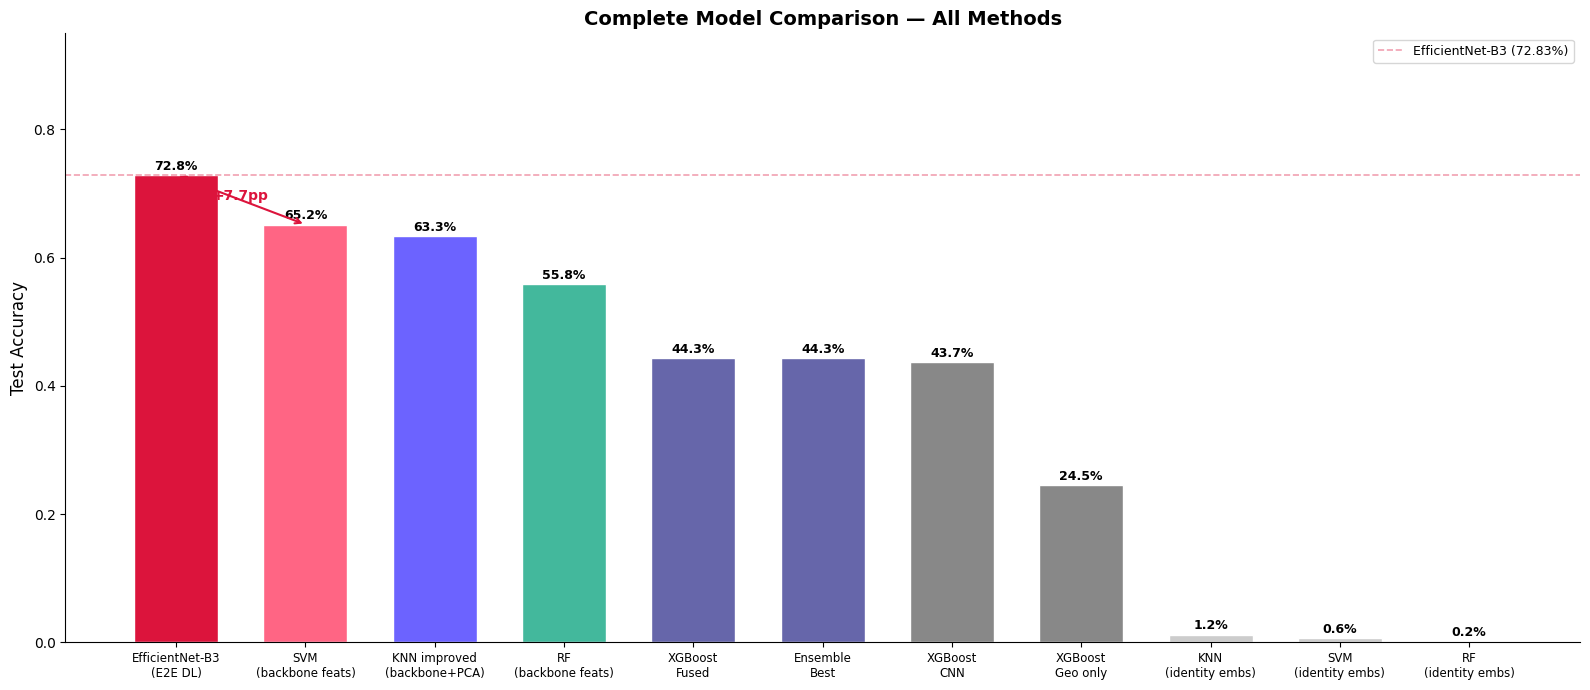


FINAL MODEL COMPARISON (UPDATED)
  Method                          Accuracy
  ------------------------------------------
  EfficientNet-B3 (E2E DL)          0.7283  (72.8%)
  SVM (backbone feats)              0.6517  (65.2%)
  KNN improved (backbone+PCA)       0.6333  (63.3%)
  RF (backbone feats)               0.5583  (55.8%)
  XGBoost Fused                     0.4429  (44.3%)
  Ensemble Best                     0.4429  (44.3%)
  XGBoost CNN                       0.4367  (43.7%)
  XGBoost Geo only                  0.2449  (24.5%)
  KNN (identity embs)               0.0120  (1.2%)
  SVM (identity embs)               0.0060  (0.6%)
  RF (identity embs)                0.0020  (0.2%)


In [82]:
# ── Updated Final Model Comparison — includes improved baselines ─────────────
import matplotlib.pyplot as plt
import numpy as np

all_results_updated = {
    "EfficientNet-B3\n(E2E DL)":    0.7283,   # true test accuracy
    "SVM\n(backbone feats)":         0.6517,   # improved experiment
    "KNN improved\n(backbone+PCA)":  0.6333,   # improved experiment
    "RF\n(backbone feats)":          0.5583,   # improved experiment
    "XGBoost\nFused":                0.4429,
    "Ensemble\nBest":                0.4429,
    "XGBoost\nCNN":                  0.4367,
    "XGBoost\nGeo only":             0.2449,
    "KNN\n(identity embs)":          0.012,
    "SVM\n(identity embs)":          0.006,
    "RF\n(identity embs)":           0.002,
}

colors = [
    "#DC143C",   # EfficientNet — red
    "#FF6584",   # SVM improved — pink
    "#6C63FF",   # KNN improved — purple
    "#43B89C",   # RF improved  — teal
    "#6666AA",   # XGBoost fused
    "#6666AA",   # Ensemble
    "#888888",   # XGBoost CNN
    "#888888",   # XGBoost Geo
    "#CCCCCC",   # KNN original
    "#CCCCCC",   # SVM original
    "#CCCCCC",   # RF original
]

fig, ax = plt.subplots(figsize=(16, 7))
names = list(all_results_updated.keys())
vals  = list(all_results_updated.values())

bars = ax.bar(range(len(names)), vals, color=colors, edgecolor="white", width=0.65)

for bar, val in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.008,
            f"{val:.1%}", ha="center", fontsize=9, fontweight="bold")

# Reference line at 72.83%
ax.axhline(0.7283, color="#DC143C", linestyle="--", linewidth=1.2,
           alpha=0.4, label="EfficientNet-B3 (72.83%)")

ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, fontsize=8.5)
ax.set_ylim(0, 0.95)
ax.set_ylabel("Test Accuracy", fontsize=12)
ax.set_title("Complete Model Comparison — All Methods", fontsize=14, fontweight="bold")
ax.legend(fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

# Annotation for the gap
ax.annotate("",
    xy=(0, 0.7283), xytext=(1, 0.6517),
    arrowprops=dict(arrowstyle="<->", color="#DC143C", lw=1.5))
ax.text(0.5, 0.69, "+7.7pp", ha="center", fontsize=10,
        fontweight="bold", color="#DC143C")

plt.tight_layout()
plt.show()
fig.savefig(str(OUTPUTS_DIR / "final_comparison_updated.png"),
            dpi=150, bbox_inches="tight")
plt.close(fig)

print("\nFINAL MODEL COMPARISON (UPDATED)")
print("=" * 55)
print(f"  {'Method':<30} {'Accuracy':>9}")
print(f"  {'-'*42}")
for name, acc in sorted(all_results_updated.items(),
                         key=lambda x: -x[1]):
    clean_name = name.replace('\n', ' ')
    print(f"  {clean_name:<30} {acc:>9.4f}  ({acc:.1%})")
print("=" * 55)

In [80]:
print("="*62)
print("  HAIRIFY - PIPELINE COMPLETE")
print("="*62)
print(f"  Classifier accuracy   : {acc:.4f} ({acc:.1%})")
print(f"  Weighted F1           : {f1:.4f}")
print(f"  Macro AUC             : {np.mean(list(auc_scores.values())):.4f}")
print(f"  Retrieval mAP         : {mAP:.4f}")
print(f"  Retrieval Recall@5    : {rec_at[5]:.4f}")
print(f"  Best ensemble         : {best} ({res[best]:.1%})")
print(f"  Best overall model    : {max(all_results, key=all_results.get)} ({max(all_results.values()):.1%})")
print(f"  Device                : {DEVICE}")
print(f"  Outputs               : {OUTPUTS_DIR}")
print("="*62)
print("\nSaved figures:")
for p in sorted(Path(OUTPUTS_DIR).glob("*.png")):
    print(f"  - {p.name}")
free()

  HAIRIFY - PIPELINE COMPLETE
  Classifier accuracy   : 0.6333 (63.3%)
  Weighted F1           : 0.5777
  Macro AUC             : 0.9227
  Retrieval mAP         : 0.0111
  Retrieval Recall@5    : 0.0044
  Best ensemble         : CNN only (44.3%)
  Best overall model    : EfficientNet-B3 (DL) (63.3%)
  Device                : cuda
  Outputs               : workdir\outputs

Saved figures:
  - all_recommendations.png
  - class_distribution.png
  - confusion_matrix.png
  - dataset_overview.png
  - ensemble_comparison.png
  - final_comparison.png
  - geometry_distributions.png
  - gradcam.png
  - hairify_dashboard.png
  - ml_comparison.png
  - optuna_results.png
  - per_class_metrics.png
  - roc_curves.png
  - training_curves.png
  - tsne.png
  - virtual_tryon.png
